# **Project Name** - Credit Card Default Prediction

##### **Project Type** - Classification
##### **Contribution** - Individual (developed with AI assistance from Claude)
##### **Team Member 1** - Sanjeev Goyal

# **Project Summary -**

Credit card lenders lose money when customers stop paying, and they lose good business when they treat every customer as a risk. This project predicts which credit card customers will default on their next payment, using the Default of Credit Card Clients dataset: 30,000 customers in Taiwan, with credit limit, demographics, and six months of repayment status, bill amounts and payments from April to September 2005. In line with the business context, the goal is more than a yes/no label. Risk managers need a reliable estimated probability of default, so the notebook judges models on ranking power (ROC-AUC and the Kolmogorov–Smirnov statistic) and on how accurate the probabilities are (Brier score and calibration), not on accuracy alone.

The work follows the project architecture: EDA, clean-up, feature engineering, pre-processing, model implementation and explainability. The data has no missing values and no duplicate customer IDs. Clean-up focused on undocumented codes: education values 0, 5 and 6 and marital status 0 were merged into "Others", while repayment status values −2 and 0, which the official documentation does not define, were kept because they carry real signal. Extreme credit limits and payments are genuine, so they were kept, with a log transform for the linear model.

Eighteen charts following the UBM rule show that 22.1% of customers default and that repayment behaviour is by far the strongest signal. Customers two months late on the latest statement default 69% of the time, against 13% for those with status code 0. Customers with no late month in the six-month window default 12% of the time, against 70% for those late in all six. Lower credit limits carry more risk, with default falling from 32% in the lowest limit band to 14% in the highest. Education, marital status and credit limit differences are statistically significant in hypothesis tests, though the education and marital status effects are small. Monthly bills of defaulters and non-defaulters look alike; what differs is how much they pay back.

Feature engineering added behavioural measures such as the number of late months, the worst delay, credit utilisation, repayment ratio and bill trend. The raw bill columns had variance inflation factors as high as 27, so they were replaced, leaving 12 numeric features with a maximum VIF of 4 and no loss in cross-validated performance. Gender was excluded because it added almost nothing to performance and is a poor basis for credit decisions. No oversampling was used: class weighting left ranking power unchanged but badly distorted the probabilities, so imbalance is handled with a stratified split and a business-chosen decision threshold.

Three models were built and tuned with randomized search and cross-validation: logistic regression, random forest and XGBoost. Tuned XGBoost performed best on the held-out test set, with a ROC-AUC of about 0.78, a K-S statistic of about 0.43 and well-calibrated probabilities. The riskiest 10% of customers default at about 70%, over three times the average, and the riskiest 30% contain over 60% of all defaults. SHAP and permutation importance both show recent repayment status and the worst delay as the dominant drivers.

The recommendation is to use the probability score for tiered action: early collection contact and limit reviews for the highest-risk tiers, and retained limits for reliable payers, with the decision threshold set by the bank's own cost of a missed default against a false alarm.

# **GitHub Link -**

**GitHub repository:** https://github.com/sanjeevgoyal1993/Credit-Card-Default-Prediction

# **Problem Statement**

This project predicts the case of customers' default payments in Taiwan. From a risk-management perspective, the predictive accuracy of the estimated **probability of default** is more valuable than a binary label of credible or not credible, and the K-S chart is used to evaluate which customers will default on their credit card payments.

Using 30,000 customers' credit limits, demographics and six months of payment history, the project answers:

- How is credit distributed across gender, and what does past payment history look like?
- Are less educated customers more likely to default? Is marital status related to default?
- Which behaviours signal default before it happens?
- Which model gives the bank the most reliable probability of default, and how should the bank act on it?

# **General Guidelines** : -

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# ---------------- Import libraries ----------------
import importlib
import subprocess
import sys
import warnings

warnings.simplefilter("ignore")           # library notices are not errors; keep the output readable


def ensure_package(module_name):
    """Install a package only if it is missing, so the notebook runs in one go on a fresh runtime."""
    try:
        importlib.import_module(module_name)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", module_name])


for package in ["xlrd", "xgboost", "statsmodels", "shap"]:
    ensure_package(package)

import joblib
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns
import shap
import sklearn
import xgboost
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor
from xgboost import XGBClassifier

RANDOM_STATE = 42                       # fixed seed: every split, search and sample is reproducible

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)

# Chart style: one axis per chart, one colour per series, quiet grid and axes
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
sns.set_theme(style="whitegrid", rc={
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 10,
    "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 100,
})

print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | shap {shap.__version__}")

python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | xgboost 3.4.1 | shap 0.54.1


### Dataset Loading

In [2]:
# ---------------- Load the dataset ----------------
# Official course file "default of credit card clients.xls" (public Google Drive link, no login needed)
DATA_URL = "https://drive.google.com/uc?export=download&id=1WSzAlD27mGG99sqCRERbHWOxZiyr8TUq"
LOCAL_FILE = "default of credit card clients.xls"    # fallback: upload this file to the Colab session

EXPECTED_COLUMNS = (
    ["ID", "LIMIT_BAL", "SEX", "EDUCATION", "MARRIAGE", "AGE", "PAY_0"]
    + [f"PAY_{i}" for i in range(2, 7)]
    + [f"BILL_AMT{i}" for i in range(1, 7)]
    + [f"PAY_AMT{i}" for i in range(1, 7)]
    + ["default payment next month"]
)


def load_data(url=DATA_URL, local_file=LOCAL_FILE):
    """Read the dataset from the public link, fall back to a local copy, and check its columns."""
    try:
        # header=1: the file's first row holds codes (X1, X2, ...), the second row holds the column names
        data = pd.read_excel(url, header=1)
        source = "public course link"
    except Exception as url_error:                   # no internet, link moved, etc.
        print(f"Could not read the link ({type(url_error).__name__}); trying '{local_file}' ...")
        try:
            data = pd.read_excel(local_file, header=1)
            source = f"local file '{local_file}'"
        except FileNotFoundError as file_error:
            raise FileNotFoundError(
                f"Dataset not found. Upload '{local_file}' to the Colab Files pane and run this cell again."
            ) from file_error

    missing_columns = sorted(set(EXPECTED_COLUMNS) - set(data.columns))
    if missing_columns:
        raise ValueError(f"The dataset is missing expected columns: {missing_columns}")

    print(f"Loaded {len(data):,} rows x {data.shape[1]} columns from the {source}.")
    return data


raw = load_data()

Loaded 30,000 rows x 25 columns from the public course link.


### Dataset First View

In [3]:
# Dataset First Look
raw.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,-2,-2,3913,3102,689,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,0,2,2682,1725,2682,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,0,0,29239,14027,13559,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,0,0,46990,48233,49291,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,0,0,8617,5670,35835,20940,19146,19131,2000,36681,10000,9000,689,679,0


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")

Rows: 30,000 | Columns: 25


### Dataset Information

In [5]:
# Dataset Info: every column is an integer and fully populated
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_A

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print(f"Duplicate rows (all columns)  : {raw.duplicated().sum()}")
print(f"Duplicate customer IDs        : {raw['ID'].duplicated().sum()}")
print(f"Duplicate rows ignoring the ID: {raw.drop(columns='ID').duplicated().sum()}")

identical = raw[raw.drop(columns="ID").duplicated(keep=False)]
zero_bills = identical[[f"BILL_AMT{i}" for i in range(1, 7)]].abs().sum(axis=1).eq(0).sum()
print(f"Customers sharing an identical profile: {len(identical)}, of which {zero_bills} have no bills at all")

Duplicate rows (all columns)  : 0
Duplicate customer IDs        : 0
Duplicate rows ignoring the ID: 35
Customers sharing an identical profile: 70, of which 60 have no bills at all


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
print(f"Total missing values: {raw.isnull().sum().sum()}")
raw.isnull().sum().to_frame("missing_values").T

Total missing values: 0


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
missing_values,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


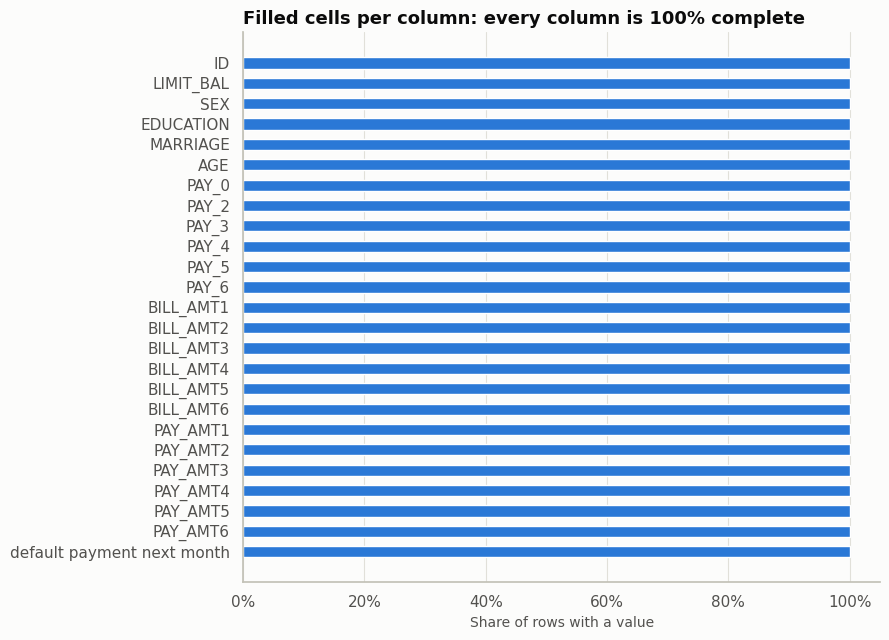

In [8]:
# Visualizing the missing values: share of filled cells per column (a gap would show as a shorter bar)
completeness = raw.notnull().mean().mul(100).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(completeness.index, completeness.values, color=BLUE, height=0.55)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_title("Filled cells per column: every column is 100% complete", loc="left")
ax.set_xlabel("Share of rows with a value")
plt.tight_layout()
plt.show()

### What did you know about your dataset?

- The dataset has **30,000 customers and 25 columns**: an ID, the target, and 23 features. The official source describes customers in Taiwan with records from April to September 2005 ([UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients)).
- All columns are stored as integers, although several are really categories (`SEX`, `EDUCATION`, `MARRIAGE`, and the six repayment status columns).
- **No missing values and no duplicate IDs.** 35 rows repeat another customer's profile once the ID is ignored; most of these customers have no bills at all, so they are plausible real customers and are kept.
- The target `default payment next month` is **imbalanced: 22.1% default**.
- Data-quality points to handle: some codes are undocumented (`EDUCATION` 0, 5, 6; `MARRIAGE` 0; repayment status −2 and 0), the repayment columns skip from `PAY_0` to `PAY_2`, and some bill amounts are negative (credit balances).

## ***2. Understanding Your Variables***

In [9]:
# Dataset Columns
print(list(raw.columns))

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


In [10]:
# Dataset Describe
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,"30,000.000","15,000.500","8,660.398",1.000,"7,500.750","15,000.500","22,500.250","30,000.000"
LIMIT_BAL,"30,000.000","167,484.323","129,747.662","10,000.000","50,000.000","140,000.000","240,000.000","1,000,000.000"
SEX,"30,000.000",1.604,0.489,1.000,1.000,2.000,2.000,2.000
EDUCATION,"30,000.000",1.853,0.790,0.000,1.000,2.000,2.000,6.000
MARRIAGE,"30,000.000",1.552,0.522,0.000,1.000,2.000,2.000,3.000
AGE,"30,000.000",35.486,9.218,21.000,28.000,34.000,41.000,79.000
PAY_0,"30,000.000",-0.017,1.124,-2.000,-1.000,0.000,0.000,8.000
PAY_2,"30,000.000",-0.134,1.197,-2.000,-1.000,0.000,0.000,8.000
PAY_3,"30,000.000",-0.166,1.197,-2.000,-1.000,0.000,0.000,8.000
PAY_4,"30,000.000",-0.221,1.169,-2.000,-1.000,0.000,0.000,8.000


### Variables Description

Meanings below come from the [official dataset page](https://archive.ics.uci.edu/dataset/350/default+of+credit+card+clients). Amounts are in New Taiwan dollars (NT\$).

| Variable | Description |
|---|---|
| `ID` | Customer identifier (dropped before modelling) |
| `LIMIT_BAL` | Amount of credit given, including the customer's individual and family credit |
| `SEX` | 1 = male, 2 = female |
| `EDUCATION` | 1 = graduate school, 2 = university, 3 = high school, 4 = others (0, 5 and 6 also appear, undocumented) |
| `MARRIAGE` | 1 = married, 2 = single, 3 = others (0 also appears, undocumented) |
| `AGE` | Age in years |
| `PAY_0`, `PAY_2` … `PAY_6` | Repayment status from September (`PAY_0`) back to April (`PAY_6`) 2005: −1 = paid duly, 1 to 9 = months of delay (−2 and 0 also appear, undocumented) |
| `BILL_AMT1` … `BILL_AMT6` | Bill statement amount from September (`BILL_AMT1`) back to April (`BILL_AMT6`) 2005 |
| `PAY_AMT1` … `PAY_AMT6` | Amount paid from September (`PAY_AMT1`) back to April (`PAY_AMT6`) 2005 |
| `default payment next month` | Target: 1 = default, 0 = no default |

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable
display(raw.nunique().sort_values(ascending=False).to_frame("unique_values").T)

# Values of the coded columns
for col in ["SEX", "EDUCATION", "MARRIAGE", "PAY_0", "PAY_2", "PAY_6"]:
    print(f"{col:10s}: {raw[col].value_counts().sort_index().to_dict()}")

,ID,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT6,PAY_AMT4,PAY_AMT5,LIMIT_BAL,AGE,PAY_2,PAY_0,PAY_4,PAY_3,PAY_5,PAY_6,EDUCATION,MARRIAGE,SEX,default payment next month
unique_values,30000,22723,22346,22026,21548,21010,20604,7943,7899,7518,6939,6937,6897,81,56,11,11,11,11,10,10,7,4,2,2


SEX       : {1: 11888, 2: 18112}
EDUCATION : {0: 14, 1: 10585, 2: 14030, 3: 4917, 4: 123, 5: 280, 6: 51}
MARRIAGE  : {0: 54, 1: 13659, 2: 15964, 3: 323}
PAY_0     : {-2: 2759, -1: 5686, 0: 14737, 1: 3688, 2: 2667, 3: 322, 4: 76, 5: 26, 6: 11, 7: 9, 8: 19}
PAY_2     : {-2: 3782, -1: 6050, 0: 15730, 1: 28, 2: 3927, 3: 326, 4: 99, 5: 25, 6: 12, 7: 20, 8: 1}
PAY_6     : {-2: 4895, -1: 5740, 0: 16286, 2: 2766, 3: 184, 4: 49, 5: 13, 6: 19, 7: 46, 8: 2}


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# ---------------- Data wrangling: cleaning ----------------
# Column groups, most recent month first (Sep, Aug, Jul, Jun, May, Apr)
PAY = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAY_AMOUNTS = [f"PAY_AMT{i}" for i in range(1, 7)]
MONTHS = ["Sep", "Aug", "Jul", "Jun", "May", "Apr"]

# Readable labels, used only in charts
SEX_LABELS = {1: "Male", 2: "Female"}
EDUCATION_LABELS = {1: "Graduate school", 2: "University", 3: "High school", 4: "Others"}
MARRIAGE_LABELS = {1: "Married", 2: "Single", 3: "Others"}


def clean_data(data):
    """Drop the ID, give columns consistent names and merge undocumented category codes into 'Others'."""
    cleaned = data.drop(columns="ID").rename(
        columns={"PAY_0": "PAY_1", "default payment next month": "DEFAULT"})
    cleaned["EDUCATION"] = cleaned["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
    cleaned["MARRIAGE"] = cleaned["MARRIAGE"].replace({0: 3})
    return cleaned


df = clean_data(raw)
print(f"EDUCATION after merge: {df['EDUCATION'].value_counts().sort_index().to_dict()}")
print(f"MARRIAGE after merge : {df['MARRIAGE'].value_counts().sort_index().to_dict()}")

EDUCATION after merge: {1: 10585, 2: 14030, 3: 4917, 4: 468}
MARRIAGE after merge : {1: 13659, 2: 15964, 3: 377}


In [13]:
# ---------------- Data wrangling: behavioural features ----------------
def add_features(data):
    """Create behavioural features. Each uses only that customer's own row, so nothing leaks between customers."""
    d = data.copy()
    d["MAX_DELAY"] = d[PAY].max(axis=1).clip(lower=0)            # worst delay in the window, in months
    d["NUM_LATE_MONTHS"] = (d[PAY] > 0).sum(axis=1)              # months with any payment delay
    d["AVG_BILL"] = d[BILL].mean(axis=1)                         # average monthly bill
    d["AVG_PAYMENT"] = d[PAY_AMOUNTS].mean(axis=1)               # average monthly payment
    d["UTILIZATION"] = (d["BILL_AMT1"] / d["LIMIT_BAL"]).clip(-1, 3)   # latest bill as a share of the limit

    # A payment in one month settles the previous month's statement, so pair Apr-Aug bills with May-Sep payments
    prior_bills = d[BILL[1:]].clip(lower=0).sum(axis=1)
    d["REPAY_RATIO"] = (d[PAY_AMOUNTS[:5]].sum(axis=1) / prior_bills.replace(0, np.nan)).clip(0, 2).fillna(1)

    d["BILL_TREND"] = ((d["BILL_AMT1"] - d["BILL_AMT6"]) / d["LIMIT_BAL"]).clip(-3, 3)   # change in debt vs limit
    return d


df = add_features(df)
OVERALL_RATE = df["DEFAULT"].mean()
print(f"Rows: {len(df):,} | Columns: {df.shape[1]} | Overall default rate: {OVERALL_RATE:.2%}")
df[["LIMIT_BAL", "PAY_1", "MAX_DELAY", "NUM_LATE_MONTHS", "UTILIZATION", "REPAY_RATIO", "BILL_TREND", "DEFAULT"]].head()

Rows: 30,000 | Columns: 31 | Overall default rate: 22.12%


,LIMIT_BAL,PAY_1,MAX_DELAY,NUM_LATE_MONTHS,UTILIZATION,REPAY_RATIO,BILL_TREND,DEFAULT
0,20000,2,2,2,0.196,0.182,0.196,1
1,120000,-1,2,2,0.022,0.208,-0.005,1
2,90000,0,0,0,0.325,0.083,0.152,0
3,50000,0,0,0,0.940,0.040,0.349,0
4,50000,-1,0,0,0.172,0.580,-0.210,0


In [14]:
# ---------------- Sanity checks: stop early if the data breaks an assumption ----------------
checks = {
    "30,000 customers kept": len(df) == 30000,
    "target is 0 or 1": set(df["DEFAULT"].unique()) == {0, 1},
    "education merged to 4 groups": set(df["EDUCATION"].unique()) == {1, 2, 3, 4},
    "marital status merged to 3 groups": set(df["MARRIAGE"].unique()) == {1, 2, 3},
    "credit limits are positive": df["LIMIT_BAL"].gt(0).all(),
    "late months are between 0 and 6": df["NUM_LATE_MONTHS"].between(0, 6).all(),
}
for check, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'} - {check}")
if not all(checks.values()):
    raise ValueError("Data checks failed - review the wrangling steps above.")

PASS - 30,000 customers kept
PASS - target is 0 or 1
PASS - education merged to 4 groups
PASS - marital status merged to 3 groups
PASS - credit limits are positive
PASS - late months are between 0 and 6


### What all manipulations have you done and insights you found?

**Manipulations**
1. Dropped `ID`, which identifies a customer but says nothing about risk.
2. Renamed `PAY_0` to `PAY_1`, so repayment columns line up with the bill and payment columns, and renamed the target to `DEFAULT`.
3. Merged undocumented codes into "Others": `EDUCATION` 0, 5, 6 (345 customers) and `MARRIAGE` 0 (54 customers).
4. Kept repayment status −2 and 0. The official page does not define them, but they behave very differently from delays, so they carry signal.
5. Kept negative bills (credit balances) and the 35 repeated profiles, because they are plausible real customers.
6. Added behavioural features: `MAX_DELAY`, `NUM_LATE_MONTHS`, `AVG_BILL`, `AVG_PAYMENT`, `UTILIZATION`, `REPAY_RATIO` and `BILL_TREND`.
7. Added sanity checks that stop the notebook if an assumption breaks.

**Insights found while wrangling**
- The data is complete, so cleaning is about meaning, not gaps.
- Delay history can be summarised in a few numbers without losing the story: how recent, how bad, how often.
- Bills should be read against the credit limit: a NT\$50,000 bill means something very different on a NT\$50,000 limit and on a NT\$500,000 limit.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

The charts follow the **UBM** rule: **univariate** (Charts 1–4), **bivariate** (Charts 5–14, 16) and **multivariate** (Charts 15, 17, 18). They also answer the questions in the project architecture: credit by gender (Chart 5), past payment history (Chart 4), education (Chart 8) and marital status (Chart 9). Most charts also print their numbers, and each measure is plotted on its own axis.

In [15]:
# ---------------- Shared chart helpers ----------------
thousands = mtick.FuncFormatter(lambda value, _: f"{value / 1000:,.0f}K")


def default_rate_table(groups):
    """Customers and default rate for each group of a Series aligned with df."""
    table = df.groupby(groups, observed=True)["DEFAULT"].agg(customers="size", default_rate="mean")
    table.index.name = "group"
    return table


def rate_chart(table, title, xlabel, figsize=(9, 4.6)):
    """Bars of default rate per group, with the overall default rate as a reference line."""
    labels = table.index.astype(str)
    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(labels, table["default_rate"] * 100, color=BLUE, width=0.55)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in table["default_rate"]], padding=3, color=INK_2)
    ax.axhline(OVERALL_RATE * 100, color=MUTED, linewidth=1)
    ax.annotate(f"Overall\n{OVERALL_RATE:.1%}", xy=(1, OVERALL_RATE * 100), xycoords=("axes fraction", "data"), xytext=(5, 0),
                textcoords="offset points", va="center", color=INK_2, fontsize=9, annotation_clip=False)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.set_ylim(0, table["default_rate"].max() * 100 * 1.15)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Default rate")
    plt.tight_layout()
    plt.show()

### **Univariate analysis**

#### Chart - 1 - Default vs no default
*Univariate – the target*

,customers,share
DEFAULT,,
No default,23364,0.779
Default,6636,0.221


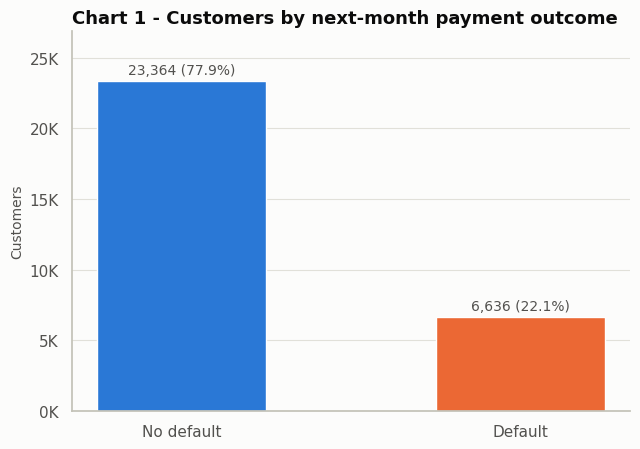

In [16]:
# Chart - 1 visualization code: how many customers default?
counts = df["DEFAULT"].value_counts().sort_index()
shares = counts / counts.sum()
display(pd.DataFrame({"customers": counts, "share": shares.round(4)}).rename(index={0: "No default", 1: "Default"}))

fig, ax = plt.subplots(figsize=(6.5, 4.6))
bars = ax.bar(["No default", "Default"], counts.values, color=[BLUE, ORANGE], width=0.5)
ax.bar_label(bars, labels=[f"{c:,} ({s:.1%})" for c, s in zip(counts, shares)], padding=3, color=INK_2)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis="x", visible=False)
ax.set_title("Chart 1 - Customers by next-month payment outcome", loc="left")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

The target has two classes, so two labelled bars show the balance at once, and the balance decides how every model must be evaluated.

##### 2. What is/are the insight(s) found from the chart?

**6,636 of 30,000 customers (22.1%) defaulted** on the next payment and 77.9% did not, about 3.5 to 1. A model that always predicts "no default" would score 77.9% accuracy while catching nobody, so accuracy cannot be the main measure.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** The base rate is the benchmark. Any risk score has to beat 22.1% to add value, and the bank can size provisions and collections capacity from it.
- **Negative:** More than one customer in five defaulting is a heavy loss rate. Growing the card book without sharper risk selection would grow those losses with it.

#### Chart - 2 - Distribution of credit limit
*Univariate – numerical*

Median 140,000 | mean 167,484 | max 1,000,000 | skewness 0.99
Most common limits: {50000: 3365, 20000: 1976, 30000: 1610, 80000: 1567}


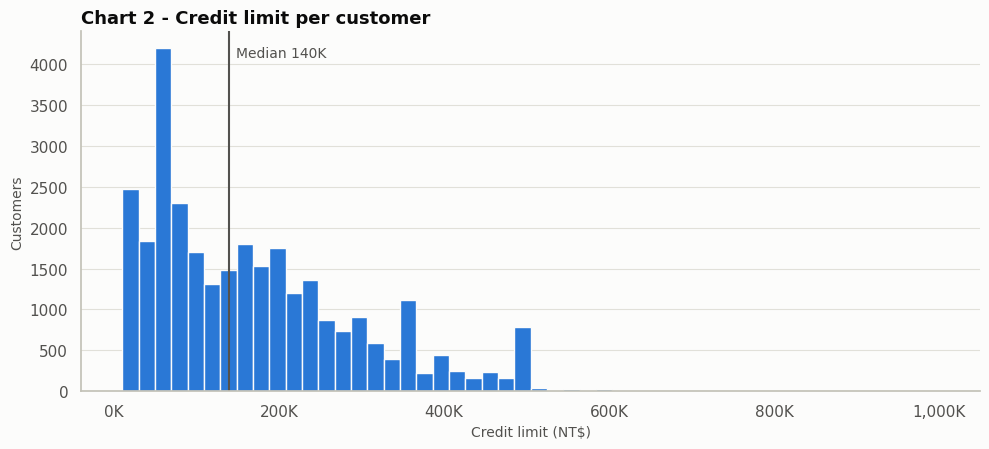

In [17]:
# Chart - 2 visualization code: how much credit do customers have?
limit = df["LIMIT_BAL"]
print(f"Median {limit.median():,.0f} | mean {limit.mean():,.0f} | max {limit.max():,.0f} | skewness {limit.skew():.2f}")
print("Most common limits:", {int(k): int(v) for k, v in limit.value_counts().head(4).items()})

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.histplot(limit, bins=50, color=BLUE, edgecolor=SURFACE, alpha=1, ax=ax)
ax.axvline(limit.median(), color=INK_2, linewidth=1.5)
ax.text(limit.median() + 8000, ax.get_ylim()[1] * 0.93, f"Median {limit.median() / 1000:,.0f}K", color=INK_2)
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="x", visible=False)
ax.set_title("Chart 2 - Credit limit per customer", loc="left")
ax.set_xlabel("Credit limit (NT$)")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows the shape of a continuous variable: its centre, spread and skew, plus any spikes a summary statistic would hide.

##### 2. What is/are the insight(s) found from the chart?

Limits are right-skewed: **median NT\$140,000**, mean NT\$167,484, maximum NT\$1,000,000. Spikes at round values show that limits follow set tiers: NT\$50,000 (3,365 customers), NT\$20,000 (1,976), NT\$30,000 (1,610) and NT\$80,000 (1,567).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Standard tiers make limit policies simple to run and review, and the high-limit customers are a natural group for retention offers.
- **Negative:** Many customers sit on low limits, where default is highest (Chart 11). Individually small exposures add up, and rounded tiers suggest limits are not closely matched to each customer's risk.

#### Chart - 3 - Distribution of age
*Univariate – numerical*

Median 34 | mean 35.5 | range 21-79 | aged 21-40: 72.4%


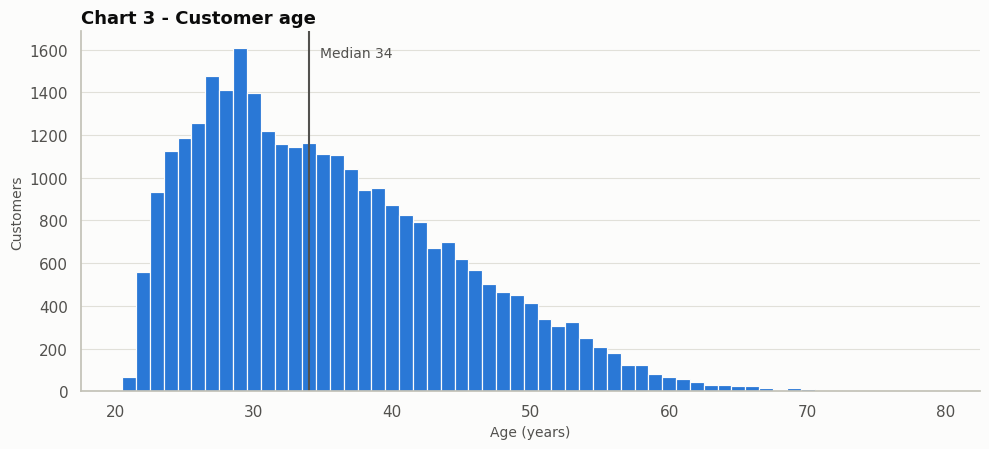

In [18]:
# Chart - 3 visualization code: how old are the customers?
age = df["AGE"]
print(f"Median {age.median():.0f} | mean {age.mean():.1f} | range {age.min()}-{age.max()} | aged 21-40: {age.between(21, 40).mean():.1%}")

fig, ax = plt.subplots(figsize=(10, 4.6))
sns.histplot(age, discrete=True, color=BLUE, edgecolor=SURFACE, alpha=1, ax=ax)
ax.axvline(age.median(), color=INK_2, linewidth=1.5)
ax.text(age.median() + 0.8, ax.get_ylim()[1] * 0.93, f"Median {age.median():.0f}", color=INK_2)
ax.grid(axis="x", visible=False)
ax.set_title("Chart 3 - Customer age", loc="left")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Age is a whole number with many values, so a histogram with one bar per year shows where customers concentrate.

##### 2. What is/are the insight(s) found from the chart?

The customer base is young: **median age 34**, mean 35.5, and **72.4% are between 21 and 40**. The oldest customer is 79.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Younger customers can stay for decades, so a good early experience has high lifetime value, and products can be designed around that group.
- **Negative:** A portfolio concentrated in younger customers depends on incomes that are still establishing, and the youngest band defaults more than the average (Chart 12).

#### Chart - 4 - Past payment history by month
*Univariate – repayment status over time*

,Apr,May,Jun,Jul,Aug,Sep
"No delay (codes -2, -1)",35.400,33.600,33.400,33.400,32.800,28.200
No delay (code 0),54.300,56.500,54.800,52.500,52.400,49.100
1 month late,0.000,0.000,0.000,0.000,0.100,12.300
2+ months late,10.300,9.900,11.700,14.000,14.700,10.400


Customers with status exactly 1 per month: {'Apr': 0, 'May': 0, 'Jun': 2, 'Jul': 4, 'Aug': 28, 'Sep': 3688}


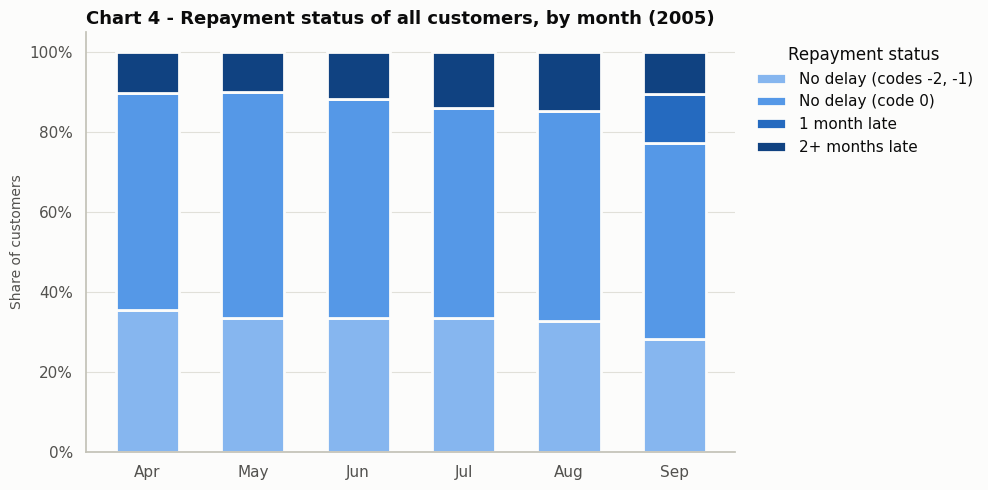

In [19]:
# Chart - 4 visualization code: what does past payment history look like?
GROUP_NAMES = ["No delay (codes -2, -1)", "No delay (code 0)", "1 month late", "2+ months late"]


def status_groups(series):
    """Group a repayment status column into four ordered classes."""
    return pd.cut(series, bins=[-3, -1, 0, 1, 9], labels=GROUP_NAMES)


history = pd.DataFrame({m: status_groups(df[c]).value_counts(normalize=True) * 100 for m, c in zip(MONTHS, PAY)})
history = history.loc[GROUP_NAMES, MONTHS[::-1]]          # good to bad, April to September
display(history.round(1))
print("Customers with status exactly 1 per month:", {m: int((df[c] == 1).sum()) for m, c in zip(MONTHS[::-1], PAY[::-1])})

ramp = ["#86b6ef", "#5598e7", "#256abf", "#104281"]       # one hue, light to dark, for ordered classes
fig, ax = plt.subplots(figsize=(10, 5))
bottom = np.zeros(history.shape[1])
for name, color in zip(GROUP_NAMES, ramp):
    ax.bar(history.columns, history.loc[name], bottom=bottom, color=color, width=0.6,
           edgecolor=SURFACE, linewidth=2, label=name)
    bottom += history.loc[name].values
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.grid(axis="x", visible=False)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", title="Repayment status")
ax.set_title("Chart 4 - Repayment status of all customers, by month (2005)", loc="left")
ax.set_ylabel("Share of customers")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A 100% stacked bar per month shows how the mix of repayment status changes over time. The classes are ordered from good to bad, so a single-hue ramp from light to dark carries that order.

##### 2. What is/are the insight(s) found from the chart?

Most customers show no delay in any month. The share at least one month late is 10.3% in April, 9.9% in May, 11.7% in June, 14.0% in July, 14.8% in August and **22.7% in September**.

Read the September jump with care. Status 1 appears 3,688 times in September, but only 28 times in August, 4 in July, 2 in June and never in April or May, so the coding seems to change. The share two or more months late is actually lower in September (10.4%) than in August (14.7%). The official documentation does not explain this.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Repayment status is updated monthly, which gives the bank a regular early-warning signal for every customer.
- **Negative:** If the late share really is rising, losses are building. The coding inconsistency also means month-on-month trend reports could mislead, so it should be resolved with the data owner.

### **Bivariate analysis**

#### Chart - 5 - Credit given over gender
*Bivariate – numerical vs categorical*

,customers,total_credit,median_limit,customer_share,credit_share
SEX,,,,,
Female,18112,3080606000,"150,000.000",0.604,0.613
Male,11888,1943923680,"130,000.000",0.396,0.387


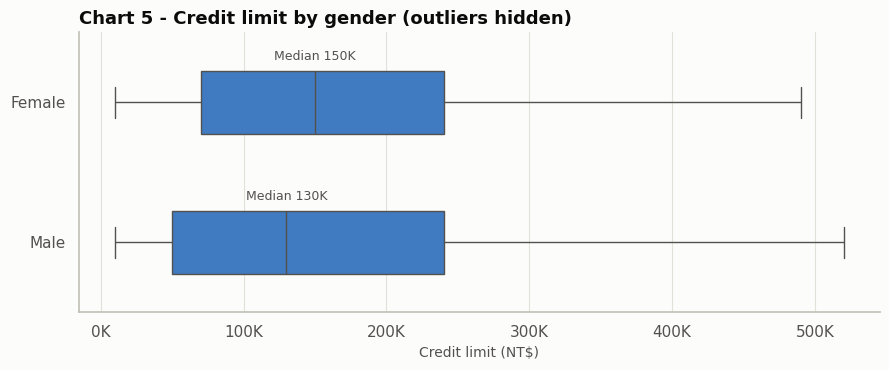

In [20]:
# Chart - 5 visualization code: how is credit distributed across gender?
gender = df["SEX"].map(SEX_LABELS)
table = df.groupby(gender)["LIMIT_BAL"].agg(customers="size", total_credit="sum", median_limit="median")
table["customer_share"] = table["customers"] / table["customers"].sum()
table["credit_share"] = table["total_credit"] / table["total_credit"].sum()
display(table.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
sns.boxplot(x=df["LIMIT_BAL"], y=gender, order=["Female", "Male"], color=BLUE, showfliers=False, width=0.45,
            linecolor=INK_2, ax=ax)
for i, name in enumerate(["Female", "Male"]):
    ax.text(table.loc[name, "median_limit"], i - 0.3, f"Median {table.loc[name, 'median_limit'] / 1000:,.0f}K",
            ha="center", color=INK_2, fontsize=9)
ax.xaxis.set_major_formatter(thousands)
ax.grid(axis="y", visible=False)
ax.set_title("Chart 5 - Credit limit by gender (outliers hidden)", loc="left")
ax.set_xlabel("Credit limit (NT$)")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the full spread of a numeric variable across categories, which is what "distribution of credit given over gender" asks. The table adds totals, which a box plot cannot show.

##### 2. What is/are the insight(s) found from the chart?

Women are **60.4% of customers and hold 61.3% of total credit**. Their median limit is NT\$150,000 against NT\$130,000 for men, and the boxes overlap heavily, so credit is spread fairly evenly across gender, slightly in women's favour.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** There is no sign that women receive less credit, which supports fair-lending reporting.
- **Negative:** A customer base skewed 60/40 may not match the wider market, so men may be under-served. Any limit policy based on gender would also be hard to justify (see Chart 10).

#### Chart - 6 - Default rate by latest repayment status
*Bivariate – categorical vs categorical*

,customers,default_rate
group,,
-2,2759,0.132
-1,5686,0.168
0,14737,0.128
1 month late,3688,0.339
2 months late,2667,0.691
3+ months late,463,0.719


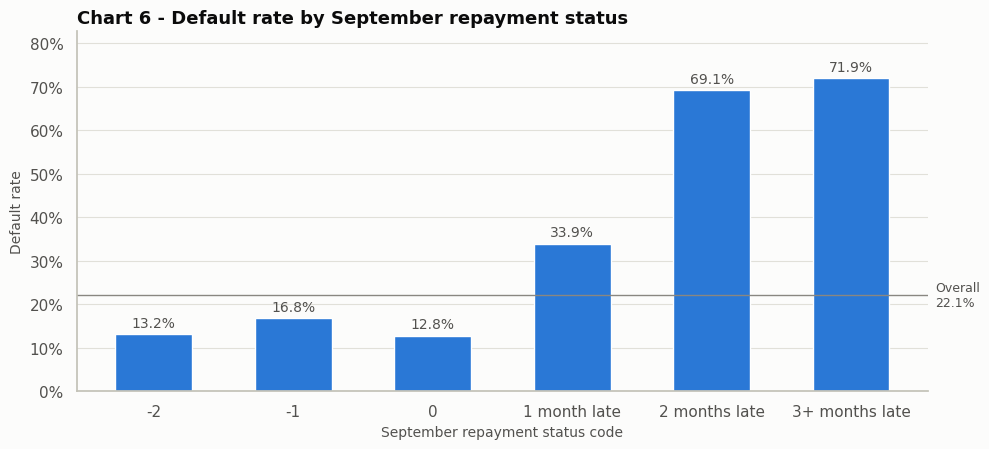

In [21]:
# Chart - 6 visualization code: how much does the latest repayment status say?
status = df["PAY_1"].clip(upper=3).map({-2: "-2", -1: "-1", 0: "0", 1: "1 month late", 2: "2 months late", 3: "3+ months late"})
order = ["-2", "-1", "0", "1 month late", "2 months late", "3+ months late"]
table = default_rate_table(pd.Categorical(status, categories=order, ordered=True))
display(table.round(3))
rate_chart(table, "Chart 6 - Default rate by September repayment status", "September repayment status code", figsize=(10, 4.6))

##### 1. Why did you pick the specific chart?

The question is how the default rate changes across the ordered status groups. One bar per group with the overall rate as a reference line makes the jump obvious.

##### 2. What is/are the insight(s) found from the chart?

This is the strongest signal in the data. Default is **12.8% at code 0**, 13.2% at −2 and 16.8% at −1, then rises to **33.9% at one month late, 69.1% at two months and 71.9% at three or more**.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** One field, updated every month, gives strong early warning. Contacting customers at one month late, before the risk more than doubles again, is a low-cost intervention.
- **Negative:** By two months late about 7 in 10 customers default, so waiting until then means most of the damage is done. The 2+ months group is also where collection costs will concentrate.

#### Chart - 7 - Default rate by number of late months
*Bivariate – numerical vs categorical*

,customers,default_rate
group,,
0,19931,0.117
1,4426,0.298
2,1899,0.388
3,1154,0.509
4,951,0.573
5,298,0.574
6,1341,0.703


Defaulters with a clean record: 2,334 of 6,636 (35.2%)


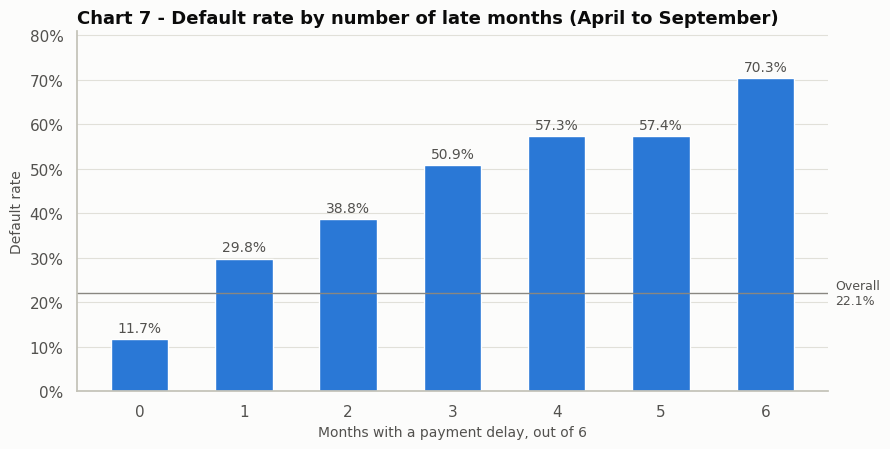

In [22]:
# Chart - 7 visualization code: does repeated lateness add risk?
table = default_rate_table(df["NUM_LATE_MONTHS"])
display(table.round(3))
clean = df[df["NUM_LATE_MONTHS"] == 0]["DEFAULT"].sum()
print(f"Defaulters with a clean record: {clean:,} of {df['DEFAULT'].sum():,} ({clean / df['DEFAULT'].sum():.1%})")
rate_chart(table, "Chart 7 - Default rate by number of late months (April to September)", "Months with a payment delay, out of 6")

##### 1. Why did you pick the specific chart?

Late months is a small whole number with a natural order, so ordered bars show whether risk climbs with each extra month.

##### 2. What is/are the insight(s) found from the chart?

Risk climbs with each late month: **11.7% with no late month** (19,931 customers), 29.8% with one, 38.8% with two, 50.9% with three, then **70.3% for customers late in all six** (1,341 customers).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** A simple count separates a large safe group from a small very risky one, so it is easy for collections teams to use. Two-thirds of customers have a clean record and can be protected from unnecessary limit cuts.
- **Negative:** Customers with a clean six months still default 11.7% of the time, and they make up about 35% of all defaulters (2,334 of 6,636), so delay history alone cannot catch everyone.

#### Chart - 8 - Default rate by education
*Bivariate – categorical vs categorical*

,customers,default_rate
group,,
Graduate school,10585,0.192
University,14030,0.237
High school,4917,0.252
Others,468,0.071


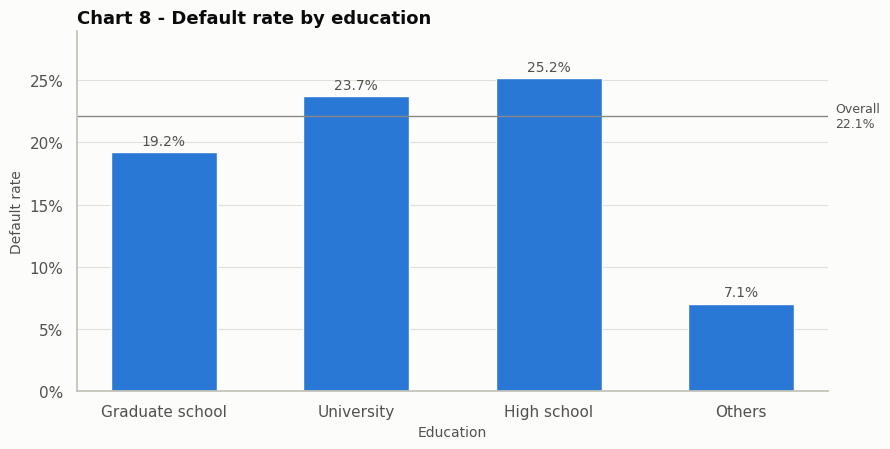

In [23]:
# Chart - 8 visualization code: are less educated people more likely to default?
order = ["Graduate school", "University", "High school", "Others"]
table = default_rate_table(pd.Categorical(df["EDUCATION"].map(EDUCATION_LABELS), categories=order, ordered=True))
display(table.round(3))
rate_chart(table, "Chart 8 - Default rate by education", "Education")

##### 1. Why did you pick the specific chart?

The project asks directly whether less educated people default more. Bars in education order, with a reference line, answer that in one look.

##### 2. What is/are the insight(s) found from the chart?

**Yes, among the three main groups:** default rises from 19.2% (graduate school) to 23.7% (university) to 25.2% (high school). "Others" sits at 7.1%, but it is only 468 customers and includes undocumented codes, so it should not be read as a real low-risk group.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Education gives some context for segment-level portfolio planning and for targeting financial-literacy support.
- **Negative:** The gap is modest: only 6 points between the main groups, against about 60 points for repayment status. Basing credit decisions on education would add little and risks treating people unfairly.

#### Chart - 9 - Default rate by marital status
*Bivariate – categorical vs categorical*

,customers,default_rate
group,,
Married,13659,0.235
Single,15964,0.209
Others,377,0.236


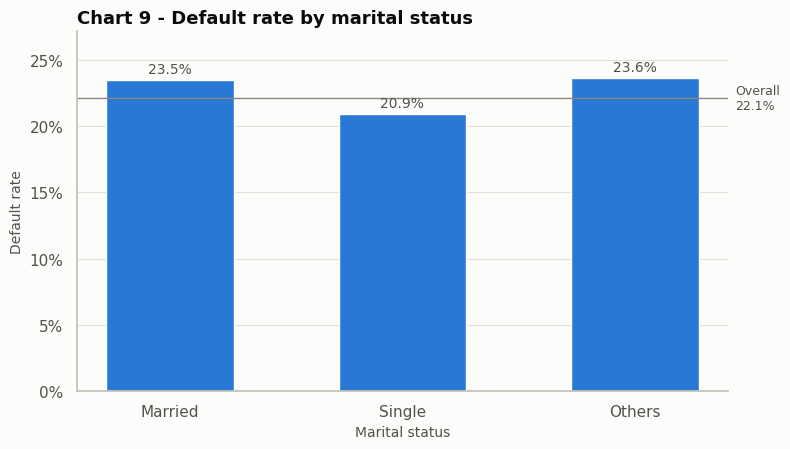

In [24]:
# Chart - 9 visualization code: is marital status related to default?
order = ["Married", "Single", "Others"]
table = default_rate_table(pd.Categorical(df["MARRIAGE"].map(MARRIAGE_LABELS), categories=order, ordered=True))
display(table.round(3))
rate_chart(table, "Chart 9 - Default rate by marital status", "Marital status", figsize=(8, 4.6))

##### 1. Why did you pick the specific chart?

The project asks whether marital status and default are related. Bars per group with a reference line show the size of any gap.

##### 2. What is/are the insight(s) found from the chart?

Married customers default slightly more (**23.5%**) than single customers (**20.9%**); "Others" is 23.6% but only 377 customers. A real difference, but only 2.6 points between the two main groups.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Marital status adds a little context to segment reporting, for example when comparing portfolios.
- **Negative:** The effect is too small to act on, and using marital status in credit decisions raises fairness concerns for very little gain.

#### Chart - 10 - Default rate by gender
*Bivariate – categorical vs categorical*

,customers,default_rate
group,,
Female,18112,0.208
Male,11888,0.242


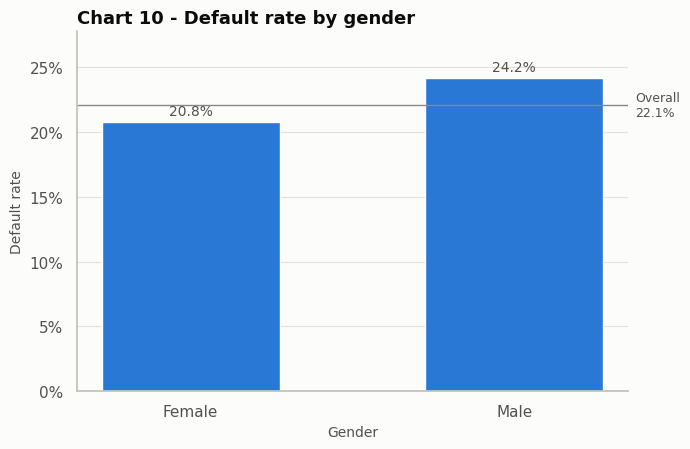

In [25]:
# Chart - 10 visualization code: does default differ by gender?
table = default_rate_table(df["SEX"].map(SEX_LABELS))
display(table.round(3))
rate_chart(table, "Chart 10 - Default rate by gender", "Gender", figsize=(7, 4.6))

##### 1. Why did you pick the specific chart?

With two groups, two bars and a reference line show the gap directly. It also informs the decision to include or exclude gender as a model feature.

##### 2. What is/are the insight(s) found from the chart?

Men default more (**24.2%**) than women (**20.8%**), a gap of 3.4 points.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Knowing the gap is small lets the bank drop gender from the model: Section 6 shows it adds almost nothing to performance once repayment behaviour is included.
- **Negative:** Treating men as riskier on gender alone would be unfair and hard to defend, and it would deny credit to many reliable male customers.

#### Chart - 11 - Default rate by credit limit
*Bivariate – numerical vs categorical*

,customers,default_rate
group,,
Up to 50K,7676,0.318
50-100K,4822,0.258
100-180K,6123,0.199
180-270K,5421,0.169
Over 270K,5958,0.138


Median limit: {'no default': 150000.0, 'default': 90000.0}


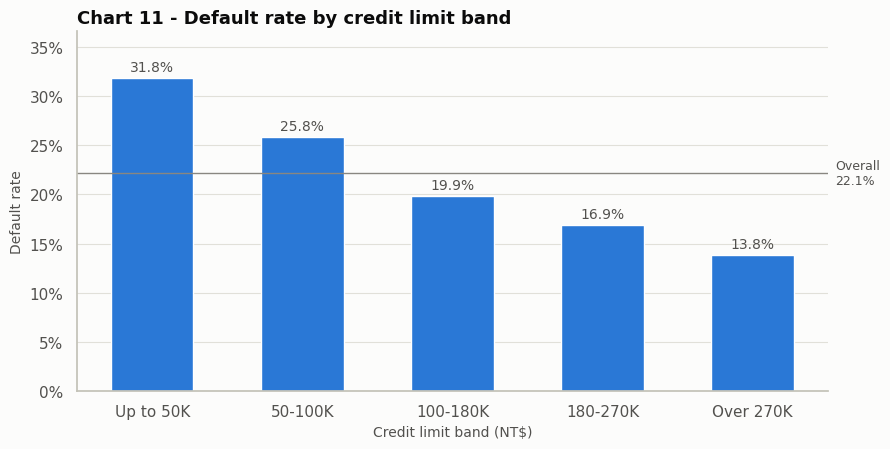

In [26]:
# Chart - 11 visualization code: are low-limit customers riskier?
bands = pd.qcut(df["LIMIT_BAL"], 5, labels=["Up to 50K", "50-100K", "100-180K", "180-270K", "Over 270K"])
table = default_rate_table(bands)
display(table.round(3))
print("Median limit:", df.groupby("DEFAULT")["LIMIT_BAL"].median().rename({0: "no default", 1: "default"}).to_dict())
rate_chart(table, "Chart 11 - Default rate by credit limit band", "Credit limit band (NT$)")

##### 1. Why did you pick the specific chart?

Grouping the skewed limit into five roughly equal groups shows the trend clearly, where a scatter of a 0/1 target would show nothing.

##### 2. What is/are the insight(s) found from the chart?

Default falls steadily as limit rises: **31.8% up to NT\$50,000**, 25.8%, 19.9%, 16.9% and **13.8% above NT\$270,000**. The median limit is NT\$90,000 for defaulters and NT\$150,000 for non-defaulters.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** The bank's limit setting already separates risk, which supports raising limits for proven low-risk customers.
- **Negative:** The lowest band holds a quarter of customers at nearly a one-in-three default rate. Growth among low-limit customers would add losses unless paired with tighter monitoring.

#### Chart - 12 - Default rate by age band
*Bivariate – numerical vs categorical*

,customers,default_rate
group,,
21-25,3871,0.267
26-30,7142,0.201
31-35,5796,0.194
36-40,4917,0.216
41-50,6005,0.233
51-60,1997,0.252
61+,272,0.268


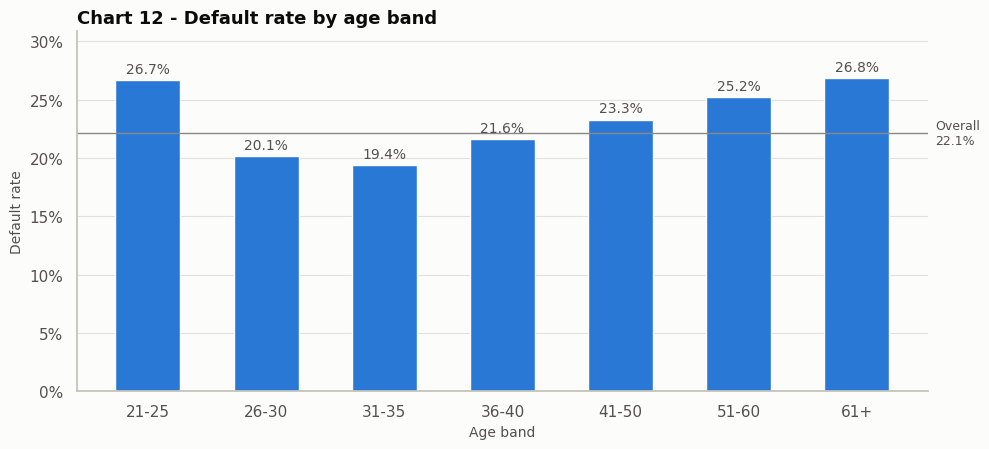

In [27]:
# Chart - 12 visualization code: does risk change with age?
bands = pd.cut(df["AGE"], bins=[20, 25, 30, 35, 40, 50, 60, 80], labels=["21-25", "26-30", "31-35", "36-40", "41-50", "51-60", "61+"])
table = default_rate_table(bands)
display(table.round(3))
rate_chart(table, "Chart 12 - Default rate by age band", "Age band", figsize=(10, 4.6))

##### 1. Why did you pick the specific chart?

Age bands in order, with a reference line, reveal a pattern that a single correlation would miss: age has almost no linear correlation with default.

##### 2. What is/are the insight(s) found from the chart?

Risk is **U-shaped**: 26.7% at 21–25, lowest at **19.4% at 31–35**, then rising to 25.2% at 51–60 and 26.8% at 61+ (only 272 customers).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** The youngest customers are a clear group for early financial-education nudges, and customers around 26–35 are the most reliable core.
- **Negative:** Older and younger customers both carry more risk, and acting on age directly can raise regulatory concerns, so behaviour should drive decisions, not age itself.

#### Chart - 13 - Default rate by credit utilisation
*Bivariate – numerical vs categorical*

,customers,default_rate
group,,
Zero or credit,2598,0.247
Up to 25%,11440,0.168
25-50%,3588,0.217
50-75%,3579,0.260
75-100%,6680,0.258
Over 100%,2115,0.301


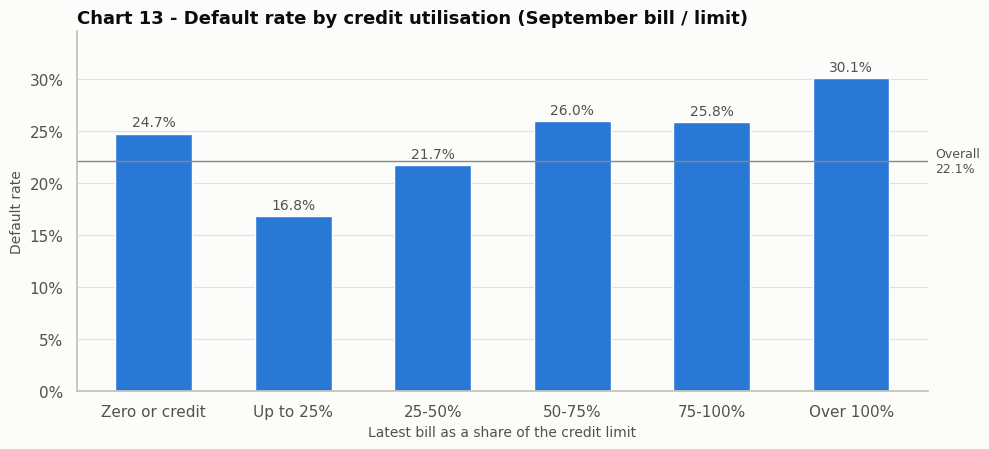

In [28]:
# Chart - 13 visualization code: is using more of the limit riskier?
bands = pd.cut(df["UTILIZATION"], bins=[-1.01, 0, 0.25, 0.5, 0.75, 1, 3.01],
               labels=["Zero or credit", "Up to 25%", "25-50%", "50-75%", "75-100%", "Over 100%"])
table = default_rate_table(bands)
display(table.round(3))
rate_chart(table, "Chart 13 - Default rate by credit utilisation (September bill / limit)", "Latest bill as a share of the credit limit", figsize=(10, 4.6))

##### 1. Why did you pick the specific chart?

Utilisation is a ratio with meaningful thresholds, so ordered bands show how risk moves as customers approach and exceed their limit.

##### 2. What is/are the insight(s) found from the chart?

Risk is lowest at **16.8% for customers using up to 25%** of their limit, climbs to about 26% at 50–100%, and reaches **30.1% for customers over their limit**. Customers with a zero or credit balance are not safe either, at 24.7%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Utilisation is easy to monitor monthly, and customers over their limit are a small group (2,115) worth an early conversation.
- **Negative:** The zero-balance group shows that "no debt" does not mean "no risk", so simple rules based on low balances would miss defaults.

#### Chart - 14 - Credit limit vs latest bill
*Bivariate – numerical vs numerical*

Pearson r = 0.285 | customers with the latest bill above their limit: 7.0%


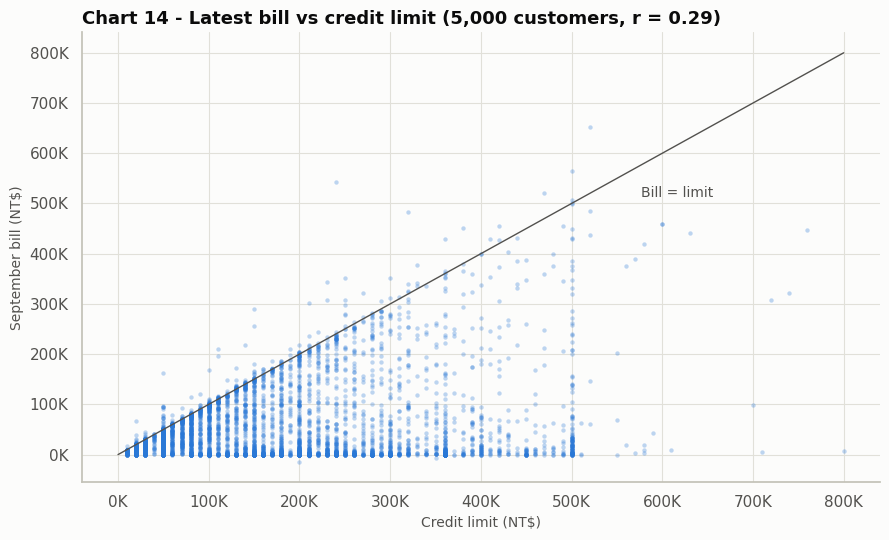

In [29]:
# Chart - 14 visualization code: how do bills relate to credit limits?
r = df["LIMIT_BAL"].corr(df["BILL_AMT1"])
over_limit = (df["BILL_AMT1"] > df["LIMIT_BAL"]).mean()
print(f"Pearson r = {r:.3f} | customers with the latest bill above their limit: {over_limit:.1%}")

sample = df.sample(5000, random_state=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(sample["LIMIT_BAL"], sample["BILL_AMT1"], s=10, color=BLUE, alpha=0.3, linewidths=0)
edge = sample["LIMIT_BAL"].max()
ax.plot([0, edge], [0, edge], color=INK_2, linewidth=1)
ax.text(edge * 0.72, edge * 0.64, "Bill = limit", color=INK_2)
ax.xaxis.set_major_formatter(thousands)
ax.yaxis.set_major_formatter(thousands)
ax.set_title(f"Chart 14 - Latest bill vs credit limit (5,000 customers, r = {r:.2f})", loc="left")
ax.set_xlabel("Credit limit (NT$)")
ax.set_ylabel("September bill (NT$)")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is the standard way to inspect two numeric variables. A reference line where the bill equals the limit shows which customers are close to it, and a sample of 5,000 keeps the points readable.

##### 2. What is/are the insight(s) found from the chart?

The two are only moderately related (**r = 0.29**): a higher limit does not mean a bigger bill. Most customers sit well below the line, and many owe almost nothing. Vertical stripes show the round limit tiers from Chart 2, and a dense edge along the line shows customers at their limit, especially on low limits. **7.0% of customers have a latest bill above their limit.**

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Most customers have plenty of unused credit, so there is room to grow spending among reliable customers without raising limits.
- **Negative:** Customers pressed against or above the line have little room left. If they are also late (Charts 6 and 13), they are a priority for early contact.

### **Multivariate and correlation analysis**

#### Chart - 15 - Average bill and payment by month and outcome
*Multivariate – month × amount × outcome*

avg_bill            avg_payment          
DEFAULT          0          1           0         1
Apr     39,042.000 38,271.000   5,719.000 3,441.000
May     40,530.000 39,540.000   5,248.000 3,219.000
Jun     43,611.000 42,037.000   5,301.000 3,156.000
Jul     47,533.000 45,182.000   5,753.000 3,367.000
Aug     49,717.000 47,284.000   6,640.000 3,389.000
Sep     51,994.000 48,509.000   6,307.000 3,397.000

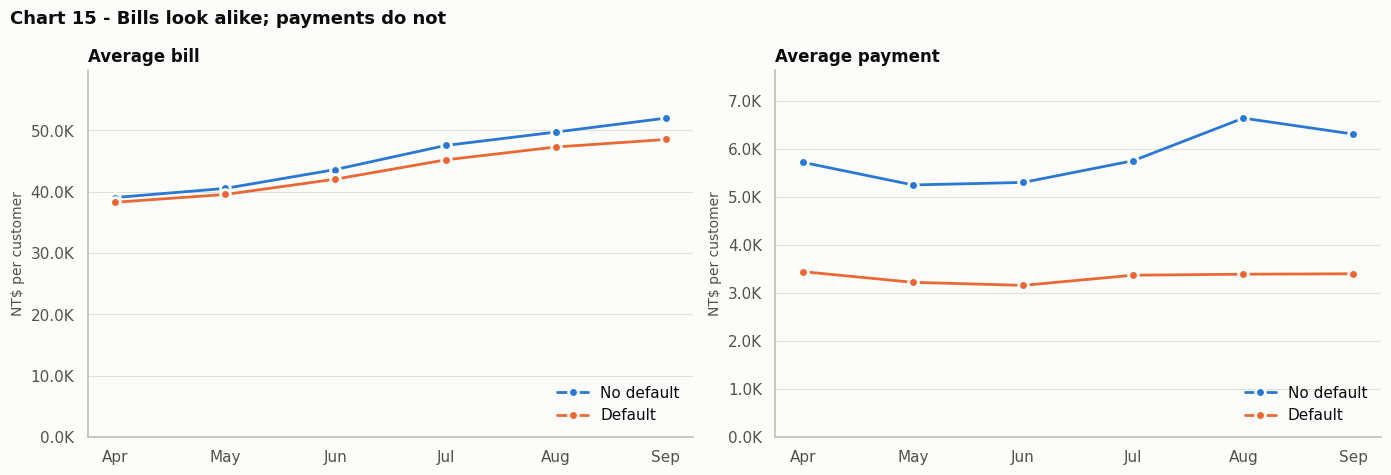

In [30]:
# Chart - 15 visualization code: do defaulters owe more, or pay less?
bills = df.groupby("DEFAULT")[BILL].mean().T
payments = df.groupby("DEFAULT")[PAY_AMOUNTS].mean().T
bills.index = payments.index = MONTHS
bills, payments = bills.iloc[::-1], payments.iloc[::-1]          # April to September
display(pd.concat({"avg_bill": bills, "avg_payment": payments}, axis=1).round(0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, data, title in [(axes[0], bills, "Average bill"), (axes[1], payments, "Average payment")]:
    ax.plot(data.index, data[0], color=BLUE, marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=2, label="No default")
    ax.plot(data.index, data[1], color=ORANGE, marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=2, label="Default")
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda value, _: f"{value / 1000:.1f}K"))
    ax.set_ylim(0, data.max().max() * 1.15)
    ax.grid(axis="x", visible=False)
    ax.set_title(title, loc="left", fontsize=12)
    ax.set_ylabel("NT$ per customer")
    ax.legend(loc="lower right")
fig.suptitle("Chart 15 - Bills look alike; payments do not", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Two line charts side by side compare both measures over time for both groups. Each has its own axis, because bills are about ten times larger than payments and a shared or dual axis would mislead.

##### 2. What is/are the insight(s) found from the chart?

**Both groups owe about the same, but non-defaulters pay back far more.** In September, bills average NT\$51,994 against NT\$48,509, while payments average NT\$6,307 against NT\$3,397. Across the six months, non-defaulters pay 1.6 to 2 times as much. Bills also grow through the window, by about a third for non-defaulters, while payments stay roughly flat.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** Payment amount is a better warning sign than bill size, so monitoring should focus on how much customers pay back.
- **Negative:** Debt rising faster than repayments is a warning for the whole portfolio. A customer's large bill alone says little about risk, so rules based only on balance would miss the point.

#### Chart - 16 - Correlation of each feature with default
*Bivariate – every numeric feature vs the target*

,LIMIT_BAL,AVG_PAYMENT,REPAY_RATIO,PAY_AMT1,PAY_AMT2,PAY_AMT4,PAY_AMT3,PAY_AMT5,PAY_AMT6,BILL_TREND,BILL_AMT1,BILL_AMT2,BILL_AMT3,AVG_BILL,BILL_AMT4,BILL_AMT5,BILL_AMT6,AGE,UTILIZATION,PAY_6,PAY_5,PAY_4,PAY_3,PAY_2,PAY_1,MAX_DELAY,NUM_LATE_MONTHS
correlation_with_default,-0.154,-0.102,-0.098,-0.073,-0.059,-0.057,-0.056,-0.055,-0.053,-0.024,-0.020,-0.014,-0.014,-0.013,-0.010,-0.007,-0.005,0.014,0.087,0.187,0.204,0.217,0.235,0.264,0.325,0.370,0.398


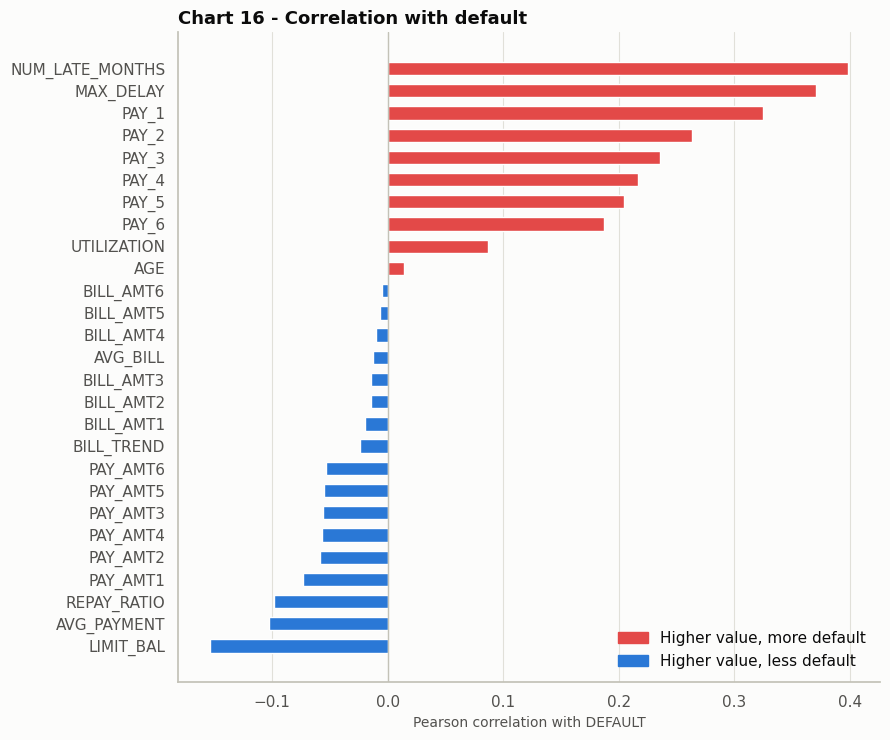

In [31]:
# Chart - 16 visualization code: which features move with default?
features = ["LIMIT_BAL", "AGE"] + PAY + BILL + PAY_AMOUNTS + ["MAX_DELAY", "NUM_LATE_MONTHS", "AVG_BILL", "AVG_PAYMENT", "UTILIZATION", "REPAY_RATIO", "BILL_TREND"]
target_corr = df[features].corrwith(df["DEFAULT"]).sort_values()
display(target_corr.round(3).to_frame("correlation_with_default").T)

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(target_corr.index, target_corr.values, color=[RED if v > 0 else BLUE for v in target_corr.values], height=0.6)
ax.axvline(0, color=AXIS, linewidth=1)
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=RED), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
          labels=["Higher value, more default", "Higher value, less default"], loc="lower right")
ax.set_title("Chart 16 - Correlation with default", loc="left")
ax.set_xlabel("Pearson correlation with DEFAULT")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Sorted bars show the sign and strength of every feature's relationship with the target at a glance, which is what feature selection needs. Two opposing colours carry the sign.

##### 2. What is/are the insight(s) found from the chart?

The strongest positive links are behaviour features: **`NUM_LATE_MONTHS` (0.40), `MAX_DELAY` (0.37)** and `PAY_1` (0.32), with older months fading from `PAY_2` (0.26) to `PAY_6` (0.19). The strongest negative links are `LIMIT_BAL` (−0.15), `AVG_PAYMENT` (−0.10) and `REPAY_RATIO` (−0.10). Bill amounts barely correlate at all (between −0.02 and 0), which matches Chart 15.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

- **Positive:** The two engineered delay features beat every raw column, which justifies the feature work and tells the bank which measures to track.
- **Negative:** Linear correlation understates non-linear effects: age looks irrelevant here (0.014) even though Chart 12 shows a clear U-shape. Relying on this chart alone would discard useful information.

#### Chart - 17 - Correlation Heatmap
*Multivariate – all raw numeric variables*

Bill columns correlate 0.80 to 0.95 with each other
Repayment status columns correlate 0.47 to 0.82 with each other
Payment columns correlate 0.15 to 0.29 with each other


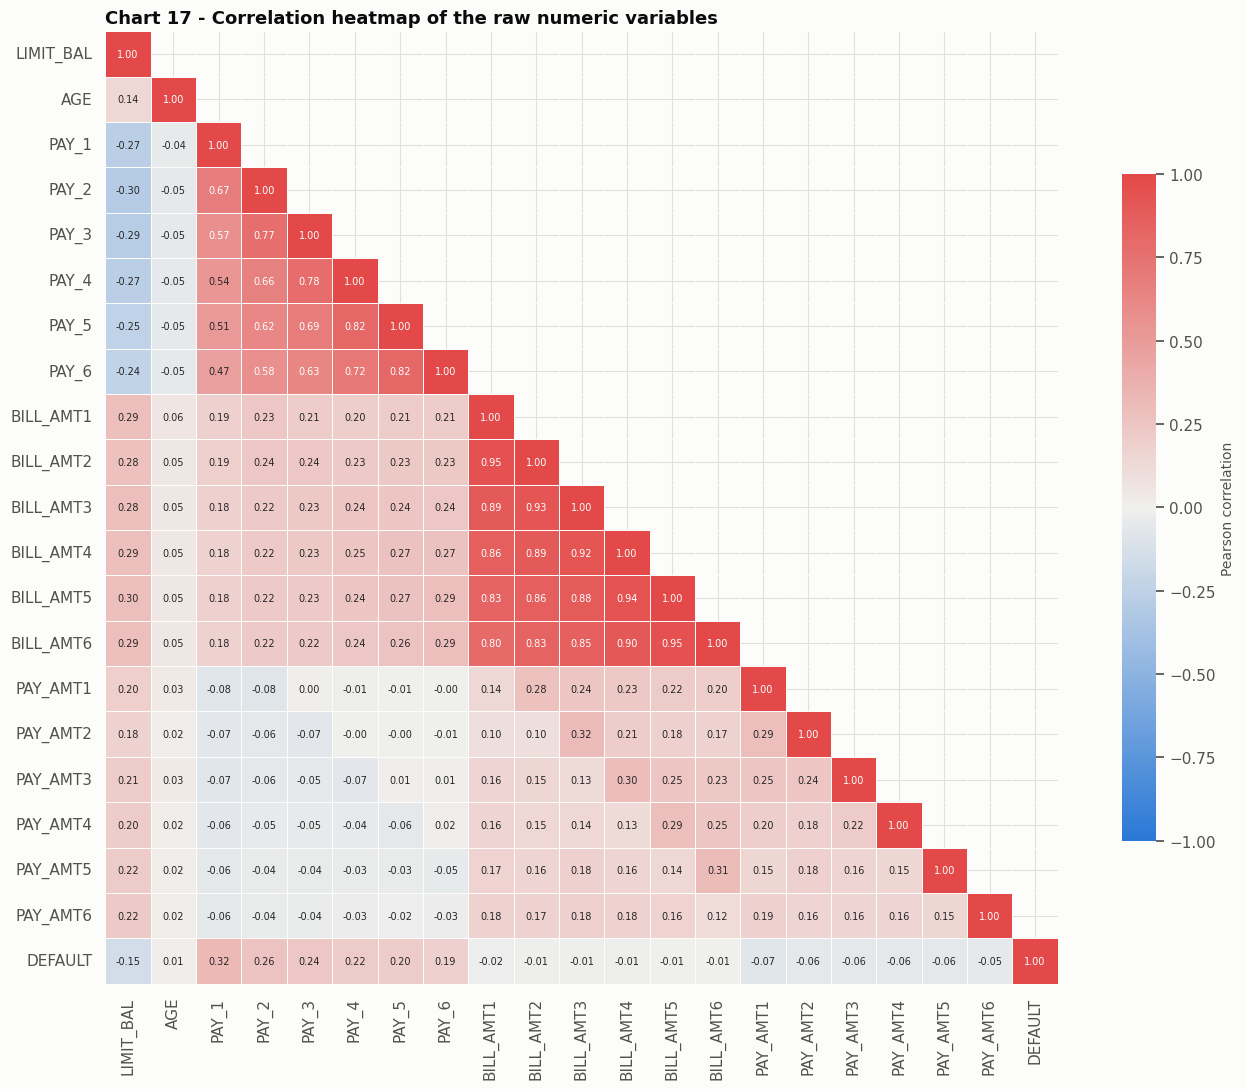

In [32]:
# Correlation Heatmap visualization code
columns = ["LIMIT_BAL", "AGE"] + PAY + BILL + PAY_AMOUNTS + ["DEFAULT"]
corr = df[columns].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)      # hide the duplicate upper triangle
diverging = LinearSegmentedColormap.from_list("blue_red", [BLUE, "#f0efec", RED])


def off_diagonal(names):
    """Correlations among a group of columns, without the 1.00 diagonal."""
    return corr.loc[names, names].where(~np.eye(len(names), dtype=bool))


print(f"Bill columns correlate {off_diagonal(BILL).min().min():.2f} to {off_diagonal(BILL).max().max():.2f} with each other")
print(f"Repayment status columns correlate {off_diagonal(PAY).min().min():.2f} to {off_diagonal(PAY).max().max():.2f} with each other")
print(f"Payment columns correlate {off_diagonal(PAY_AMOUNTS).min().min():.2f} to {off_diagonal(PAY_AMOUNTS).max().max():.2f} with each other")

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap=diverging, vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, linecolor=SURFACE, cbar_kws={"shrink": 0.7, "label": "Pearson correlation"}, ax=ax)
ax.set_title("Chart 17 - Correlation heatmap of the raw numeric variables", loc="left")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap summarises every pairwise linear relationship in one view, and it is the quickest way to spot redundant columns before modelling. Blue and red poles with a neutral midpoint separate negative from positive.

##### 2. What is/are the insight(s) found from the chart?

**The six bill columns are near copies of each other** (0.80 to 0.95), and the repayment status columns are also strongly related (0.47 to 0.82), so much of that information is redundant. Payment columns are only weakly related to each other (0.15 to 0.29), so each month's payment adds something new. No raw column has a strong linear link with default: the largest is `PAY_1` at 0.32.

#### Chart - 18 - Pair Plot
*Multivariate – key features by outcome*

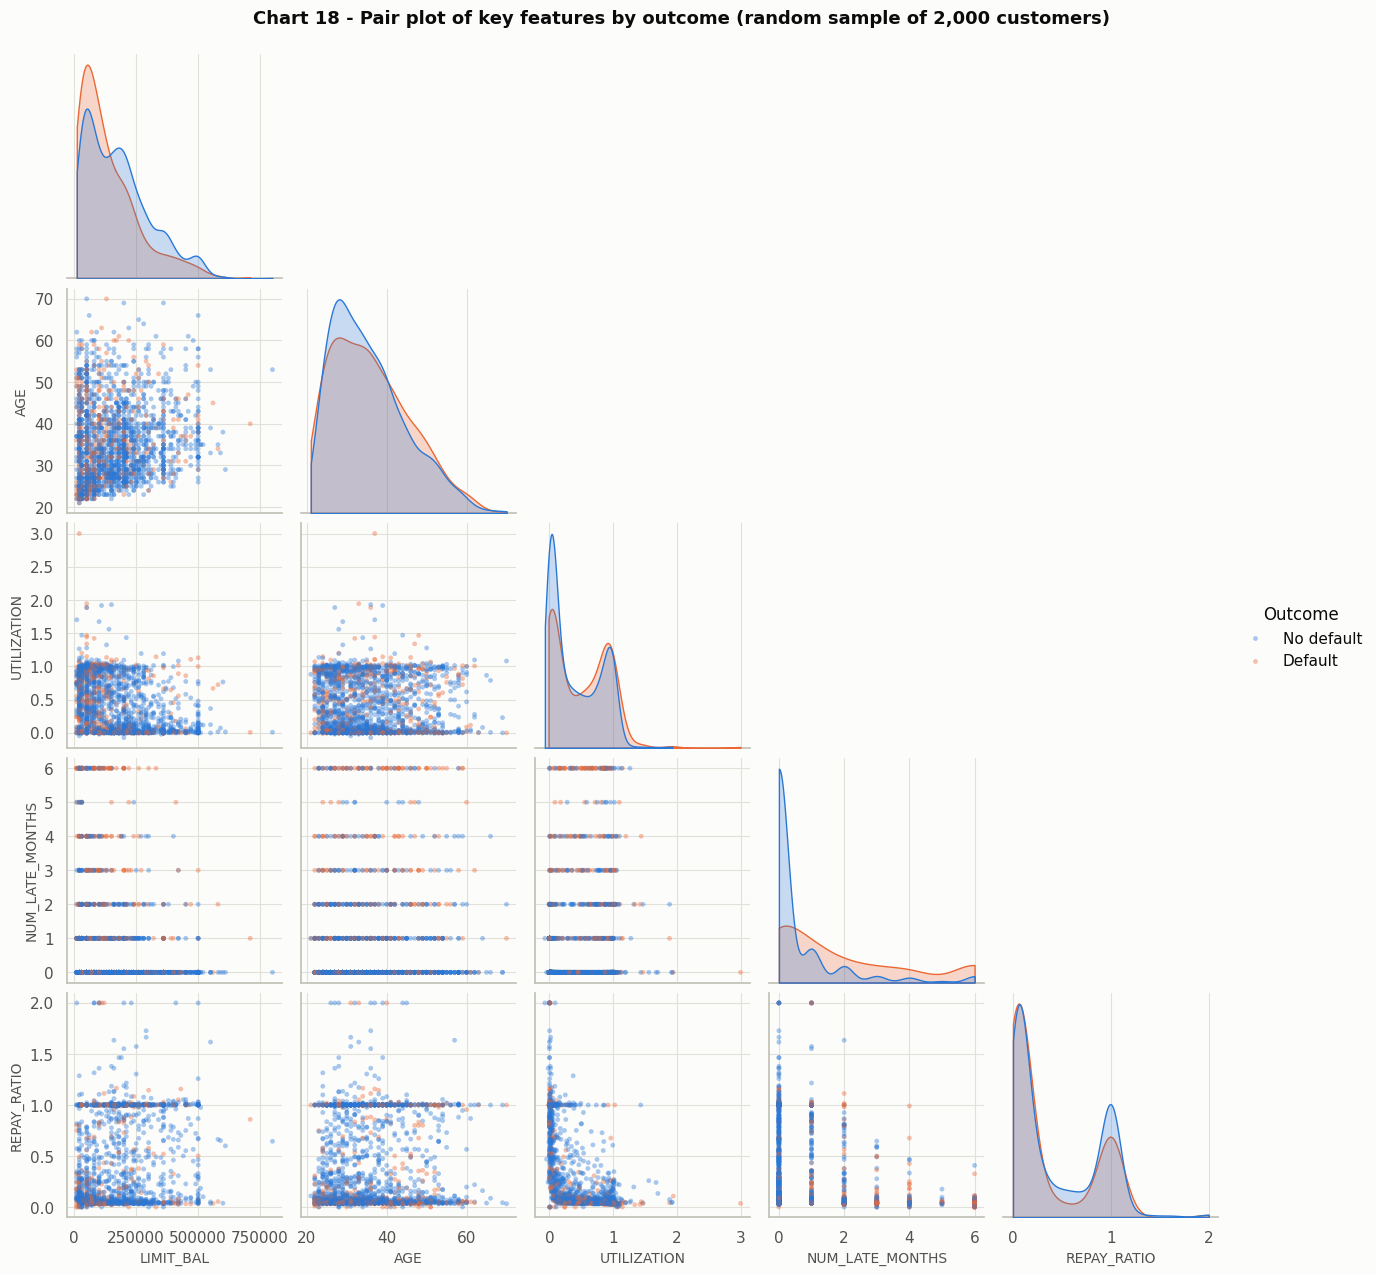

In [33]:
# Pair Plot visualization code (random sample for speed and readability)
PAIR_COLUMNS = ["LIMIT_BAL", "AGE", "UTILIZATION", "NUM_LATE_MONTHS", "REPAY_RATIO"]
pair_data = df[PAIR_COLUMNS].sample(2000, random_state=RANDOM_STATE)
pair_data["Outcome"] = df.loc[pair_data.index, "DEFAULT"].map({0: "No default", 1: "Default"})

grid = sns.pairplot(pair_data, vars=PAIR_COLUMNS, hue="Outcome", hue_order=["No default", "Default"],
                    palette={"No default": BLUE, "Default": ORANGE}, corner=True,
                    plot_kws={"alpha": 0.4, "s": 12, "linewidth": 0}, diag_kws={"common_norm": False, "cut": 0})
grid.figure.suptitle("Chart 18 - Pair plot of key features by outcome (random sample of 2,000 customers)",
                     y=1.02, fontsize=13, fontweight="bold")
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows every pairwise scatter plus each feature's distribution by outcome, as a final multivariate check for patterns the earlier charts may have missed. A sample of 2,000 keeps it fast and readable.

##### 2. What is/are the insight(s) found from the chart?

`NUM_LATE_MONTHS` separates the outcomes best: non-defaulters pile up at zero, while defaulters spread across all values. `UTILIZATION` and `REPAY_RATIO` each have two peaks, near 0 and near 1: customers tend to use little or sit near their limit, and to pay little or pay in full. Defaulters lean towards high utilisation, low repayment and lower limits, while age looks nearly the same for both groups. No pair of features separates the two colours cleanly, which is why a model combining many weak signals is needed.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the charts, the three statements are:

1. Default depends on education (Chart 8).
2. Default depends on marital status (Chart 9).
3. Customers who default have lower credit limits than customers who do not (Chart 11).

Each test uses a 5% significance level. With 30,000 customers even tiny differences can be statistically significant, so each test also reports an effect size.

In [34]:
# ---------------- Helper for the two chi-square tests ----------------
ALPHA = 0.05


def chi_square_test(column):
    """Chi-square test of independence between a categorical column and DEFAULT, with Cramer's V as effect size."""
    table = pd.crosstab(df[column], df["DEFAULT"])
    chi2, p_value, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    print(f"Chi-square = {chi2:.1f} | degrees of freedom = {dof} | p-value = {p_value:.2e} | Cramer's V = {cramers_v:.3f}")
    print("Reject the null hypothesis" if p_value < ALPHA else "Fail to reject the null hypothesis")

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** default is independent of education.
- **Alternate hypothesis (H1):** default depends on education.

#### 2. Perform an appropriate statistical test.

In [35]:
# Perform Statistical Test to obtain P-Value
chi_square_test("EDUCATION")

Chi-square = 160.4 | degrees of freedom = 3 | p-value = 1.50e-34 | Cramer's V = 0.073
Reject the null hypothesis


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence.

##### Why did you choose the specific statistical test?

Both variables are categorical and the question is whether they are independent. Every cell of the table has far more than five expected customers, so the test's conditions hold. Result: **education and default are related (p far below 0.05), but the effect is small (Cramér's V about 0.07)**.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** default is independent of marital status.
- **Alternate hypothesis (H1):** default depends on marital status.

#### 2. Perform an appropriate statistical test.

In [36]:
# Perform Statistical Test to obtain P-Value
chi_square_test("MARRIAGE")

Chi-square = 28.1 | degrees of freedom = 2 | p-value = 7.79e-07 | Cramer's V = 0.031
Reject the null hypothesis


##### Which statistical test have you done to obtain P-Value?

Chi-square test of independence.

##### Why did you choose the specific statistical test?

It is the right test for two categorical variables with large expected counts. Result: **marital status and default are related (p far below 0.05), but the effect is very small (Cramér's V about 0.03)**.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

- **Null hypothesis (H0):** the credit limits of defaulters are not lower than those of non-defaulters.
- **Alternate hypothesis (H1):** the credit limits of defaulters are lower than those of non-defaulters.

#### 2. Perform an appropriate statistical test.

In [37]:
# Perform Statistical Test to obtain P-Value
defaulters = df.loc[df["DEFAULT"] == 1, "LIMIT_BAL"]
non_defaulters = df.loc[df["DEFAULT"] == 0, "LIMIT_BAL"]
u_stat, p_value = stats.mannwhitneyu(defaulters, non_defaulters, alternative="less")
rank_biserial = 1 - 2 * u_stat / (len(defaulters) * len(non_defaulters))   # effect size: 0 = none, 1 = complete separation
print(f"Median limit: defaulters {defaulters.median():,.0f} | non-defaulters {non_defaulters.median():,.0f}")
print(f"Mann-Whitney U = {u_stat:,.0f} | p-value = {p_value:.2e} | rank-biserial effect size = {rank_biserial:.3f}")
print("Reject the null hypothesis" if p_value < ALPHA else "Fail to reject the null hypothesis")

Median limit: defaulters 90,000 | non-defaulters 150,000
Mann-Whitney U = 59,257,218 | p-value = 6.13e-190 | rank-biserial effect size = 0.236
Reject the null hypothesis


##### Which statistical test have you done to obtain P-Value?

One-sided Mann-Whitney U test.

##### Why did you choose the specific statistical test?

Credit limit is skewed (Chart 2), so a test that compares ranks is safer than a t-test, which assumes roughly normal data, and it needs no transformation. The test is one-sided because the statement has a direction. Result: **defaulters have significantly lower limits (median NT\$90,000 against NT\$150,000)**, and this effect is clearly larger than the education and marital status effects.

## ***6. Feature Engineering & Data Pre-processing***

In [38]:
# Hold out the test set first, so every selection decision below uses training data only
train_idx, test_idx = train_test_split(df.index, test_size=0.2, stratify=df["DEFAULT"], random_state=RANDOM_STATE)
print(f"Training rows: {len(train_idx):,} | Test rows: {len(test_idx):,}")

Training rows: 24,000 | Test rows: 6,000


### 1. Handling Missing Values

In [39]:
# Handling Missing Values & Missing Value Imputation
print(f"Missing values in the cleaned data: {df.isnull().sum().sum()}")
no_prior_bills = df[BILL[1:]].clip(lower=0).sum(axis=1).eq(0)
print(f"Customers with no April-August bills, so REPAY_RATIO has no denominator: {no_prior_bills.sum():,} ({no_prior_bills.mean():.1%})")
print(f"Their default rate: {df.loc[no_prior_bills, 'DEFAULT'].mean():.1%}")

Missing values in the cleaned data: 0
Customers with no April-August bills, so REPAY_RATIO has no denominator: 1,406 (4.7%)
Their default rate: 31.2%


#### What all missing value imputation techniques have you used and why did you use those techniques?

The raw data has no missing values, so no imputation was needed. One engineered feature needed a decision: `REPAY_RATIO` divides payments by earlier bills, which is undefined for customers with no earlier bills. Those customers were given a value of 1, meaning "nothing left unpaid", because that is what the situation means. A statistical fill such as the median would have invented a repayment behaviour they never had. These 1,406 customers default at 31.2%, above average, which matches Chart 13: no earlier debt does not mean no risk. The tree models can still separate them using their other features.

### 2. Handling Outliers

In [40]:
# Handling Outliers & Outlier treatments
def iqr_outlier_share(series):
    """Share of values outside the 1.5 x IQR fences."""
    q1, q3 = series.quantile([0.25, 0.75])
    fence = 1.5 * (q3 - q1)
    return ((series < q1 - fence) | (series > q3 + fence)).mean()


outliers = pd.DataFrame({
    "iqr_outlier_share": {c: iqr_outlier_share(df[c]) for c in ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "AVG_PAYMENT"]},
    "maximum": df[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "AVG_PAYMENT"]].max(),
    "skewness": df[["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1", "AVG_PAYMENT"]].skew(),
})
display(outliers.round(3))

,iqr_outlier_share,maximum,skewness
LIMIT_BAL,0.006,"1,000,000.000",0.993
AGE,0.009,79.000,0.732
BILL_AMT1,0.080,"964,511.000",2.664
PAY_AMT1,0.092,"873,552.000",14.668
AVG_PAYMENT,0.097,"627,344.333",14.617


##### What all outlier treatment techniques have you used and why did you use those techniques?

**No rows were removed.** The extreme values are genuine: a large credit limit or a large one-off payment is real behaviour, and high payers are exactly the customers the model should learn from. Instead:

- Tree-based models need no treatment, because they split on order rather than distance.
- The logistic regression gets a signed log transform (see Data Transformation below), which pulls in the long tail while keeping negative balances valid.
- Ratio features (`UTILIZATION`, `REPAY_RATIO`, `BILL_TREND`) were clipped when created, so a tiny denominator cannot produce a meaningless extreme.

### 3. Categorical Encoding

In [41]:
# Encode your categorical columns
CATEGORICAL_FEATURES = ["EDUCATION", "MARRIAGE"]
encoder = OneHotEncoder(handle_unknown="ignore").fit(df.loc[train_idx, CATEGORICAL_FEATURES])
print("Columns after one-hot encoding:", list(encoder.get_feature_names_out()))

Columns after one-hot encoding: ['EDUCATION_1', 'EDUCATION_2', 'EDUCATION_3', 'EDUCATION_4', 'MARRIAGE_1', 'MARRIAGE_2', 'MARRIAGE_3']


#### What all categorical encoding techniques have you used & why did you use those techniques?

**One-hot encoding** for `EDUCATION` and `MARRIAGE`, because their numeric codes are labels: marital status has no order, and "Others" sits outside any education order. Encoding happens inside each model's pipeline, so it is learned from training folds only.

The repayment status columns stay numeric because their order is meaningful: a bigger number means a longer delay. `SEX` is left out on purpose, as explained under Feature Selection.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

**Not applicable.** This dataset has no text columns, so the text pre-processing steps in the template do not apply.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [42]:
# Manipulate Features to minimize feature correlation and create new features
def vif_table(columns):
    """Variance inflation factor per column, measured on the training rows after standardising."""
    values = df.loc[train_idx, columns].astype(float)
    values = (values - values.mean()) / values.std()
    return pd.Series([variance_inflation_factor(values.values, i) for i in range(len(columns))], index=columns)


raw_amounts = ["LIMIT_BAL", "AGE"] + BILL + PAY_AMOUNTS
print("VIF of the raw amount columns (above 5 to 10 signals a problem):")
display(vif_table(raw_amounts).round(1).to_frame("VIF").T)

# Replace the six near-duplicate bill columns with behaviour measured against the credit limit,
# keep only the two most recent status and payment months, and summarise the rest
NUMERIC_FEATURES = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "MAX_DELAY", "NUM_LATE_MONTHS", "UTILIZATION",
                    "BILL_TREND", "PAY_AMT1", "PAY_AMT2", "AVG_PAYMENT", "REPAY_RATIO"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("VIF of the selected numeric features:")
selected_vif = vif_table(NUMERIC_FEATURES)
display(selected_vif.round(1).to_frame("VIF").T)
print(f"Largest VIF: raw columns {vif_table(raw_amounts).max():.1f} -> selected features {selected_vif.max():.1f}")

VIF of the raw amount columns (above 5 to 10 signals a problem):


,LIMIT_BAL,AGE,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6
VIF,1.200,1.000,13.600,27.200,24.700,20.600,24.100,14.700,1.700,2.100,1.800,1.600,1.600,1.200


VIF of the selected numeric features:


,LIMIT_BAL,AGE,PAY_1,PAY_2,MAX_DELAY,NUM_LATE_MONTHS,UTILIZATION,BILL_TREND,PAY_AMT1,PAY_AMT2,AVG_PAYMENT,REPAY_RATIO
VIF,1.500,1.000,2.300,3.200,3.400,4.000,3.200,1.700,1.700,1.800,3.000,2.700


Largest VIF: raw columns 27.2 -> selected features 4.0


#### 2. Feature Selection

In [43]:
# Select your features wisely to avoid overfitting
def tree_preprocessor():
    """One-hot encode the categories and pass the numeric columns through unchanged."""
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES)],
                             remainder="passthrough", verbose_feature_names_out=False)


def quick_xgb(**extra):
    """A fixed, moderate XGBoost used to compare options fairly before any tuning.

    Each model uses one thread (n_jobs=1) because the cross-validation runs in parallel instead. XGBoost's random
    sampling differs slightly between operating systems, so a run on Windows may not match this Colab (Linux) run exactly.
    """
    return XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                         eval_metric="logloss", tree_method="hist", n_jobs=1, random_state=RANDOM_STATE, **extra)


cv5 = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
candidates = {
    "All raw columns (20 numeric)": ["LIMIT_BAL", "AGE"] + PAY + BILL + PAY_AMOUNTS + CATEGORICAL_FEATURES,
    "Selected features (12 numeric)": FEATURES,
    "Selected features + SEX": FEATURES + ["SEX"],
}
comparison = {}
for name, columns in candidates.items():
    pipeline = Pipeline([("prep", tree_preprocessor()), ("clf", quick_xgb())])
    scores = cross_val_score(pipeline, df.loc[train_idx, columns], df.loc[train_idx, "DEFAULT"], cv=cv5, scoring="roc_auc")
    comparison[name] = {"cv_roc_auc": scores.mean(), "std": scores.std()}
display(pd.DataFrame(comparison).T)

,cv_roc_auc,std
All raw columns (20 numeric),0.783,0.007
Selected features (12 numeric),0.785,0.005
Selected features + SEX,0.786,0.005


##### What all feature selection methods have you used  and why?

Three methods, all on training data:

1. **Correlation analysis** (Charts 16 and 17) exposed six near-duplicate bill columns and fading older status months.
2. **Variance inflation factor (VIF):** multicollinearity makes logistic regression coefficients unstable, so columns were replaced until every VIF was below 5. The largest VIF fell from **27.2 to 4.0**.
3. **Domain judgement checked by cross-validation:** the same XGBoost was scored on each candidate set. The 12 selected numeric features score a ROC-AUC of **0.785**, against 0.783 with all 20 raw numeric columns, so the smaller set loses nothing.

**`SEX` was excluded.** Adding it moves the score by only 0.001 (0.786 against 0.785), far less than the 0.005 spread between folds, so it brings no real benefit, and gender is a poor basis for a credit decision.

##### Which all features you found important and why?

**Recent and repeated lateness** (`PAY_1`, `MAX_DELAY`, `NUM_LATE_MONTHS`) matters most, because past payment behaviour is the most direct evidence of future behaviour (Charts 6 and 7). Next come **how much customers pay** (`AVG_PAYMENT`, Chart 15), **how much of their limit they use** (`UTILIZATION`, Chart 13) and **the credit limit** itself (`LIMIT_BAL`, Chart 11), which reflects the bank's earlier view of the customer. Section 7 confirms this on the test set with permutation importance and SHAP.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [44]:
# Transform Your data
def signed_log(values):
    """Log transform that also works for negative amounts such as credit balances."""
    return np.sign(values) * np.log1p(np.abs(values))


SKEWED_FEATURES = ["LIMIT_BAL", "PAY_AMT1", "PAY_AMT2", "AVG_PAYMENT"]
train_amounts = df.loc[train_idx, SKEWED_FEATURES]
display(pd.DataFrame({"skew_before": train_amounts.skew(), "skew_after": signed_log(train_amounts).skew()}).round(2))

,skew_before,skew_after
LIMIT_BAL,1.000,-0.520
PAY_AMT1,15.310,-1.300
PAY_AMT2,21.120,-1.240
AVG_PAYMENT,14.870,-2.180


**Yes, for the logistic regression only.** The money columns are strongly right-skewed, which lets a few very large values dominate a linear model, so they get a signed log transform. Tree-based models split on order, so they are unaffected and receive the values unchanged.

### 6. Data Scaling

In [45]:
# Scaling your data
def linear_preprocessor():
    """Log and scale skewed amounts, scale other numbers and one-hot encode categories, for the linear model."""
    other_numeric = [c for c in NUMERIC_FEATURES if c not in SKEWED_FEATURES]
    return ColumnTransformer([
        ("amounts", Pipeline([("log", FunctionTransformer(signed_log)), ("scale", StandardScaler())]), SKEWED_FEATURES),
        ("numeric", StandardScaler(), other_numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAL_FEATURES),
    ], verbose_feature_names_out=False)


scaled_check = linear_preprocessor().fit_transform(df.loc[train_idx, FEATURES])
print(f"Shape after pre-processing: {scaled_check.shape} | mean of the first scaled column: {scaled_check[:, 0].mean():.3f} | std: {scaled_check[:, 0].std():.3f}")

Shape after pre-processing: (24000, 17) | mean of the first scaled column: -0.000 | std: 1.000


##### Which method have you used to scale you data and why?

**StandardScaler**, for the logistic regression only. Regularisation penalises coefficients by size, so features must be on a comparable scale for the penalty to be fair. It suits features after the log transform, which are roughly bell-shaped, and it is less affected by remaining extremes than min-max scaling. The scaler sits inside the pipeline, so it is fitted on training folds only. Tree models need no scaling.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

**No.** After feature selection there are only 12 numeric features with low multicollinearity, against 24,000 training rows, so overfitting from too many dimensions is not a concern. The check below confirms that compression would gain little, and reduced components would lose the plain-language meaning that a credit decision needs.

In [46]:
# DImensionality Reduction (If needed): a check only; the components are not used in the models
pca = PCA().fit(StandardScaler().fit_transform(df.loc[train_idx, NUMERIC_FEATURES]))
cumulative = np.cumsum(pca.explained_variance_ratio_)
print(f"Components needed out of {len(NUMERIC_FEATURES)}: {np.argmax(cumulative >= 0.90) + 1} for 90% of the variance, {np.argmax(cumulative >= 0.95) + 1} for 95%")

Components needed out of 12: 7 for 90% of the variance, 9 for 95%


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

None was applied. PCA was run only as a check, and it confirmed there is little to gain.

### 8. Data Splitting

In [47]:
# Split your data to train and test. Choose Splitting ratio wisely.
X_train, X_test = df.loc[train_idx, FEATURES], df.loc[test_idx, FEATURES]
y_train, y_test = df.loc[train_idx, "DEFAULT"], df.loc[test_idx, "DEFAULT"]
print(f"X_train {X_train.shape} | X_test {X_test.shape}")
print(f"Default rate: train {y_train.mean():.2%} | test {y_test.mean():.2%}")

X_train (24000, 14) | X_test (6000, 14)
Default rate: train 22.12% | test 22.12%


##### What data splitting ratio have you used and why?

**80% train, 20% test, stratified on the target.** With 30,000 customers, 20% still gives 6,000 test customers, including about 1,300 defaulters, which is enough for stable metrics, while 24,000 rows leave plenty for training and cross-validation. Stratifying keeps the 22% default rate the same in both parts. The test set is used only for final evaluation; all tuning uses cross-validation on the training set.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

**Yes, moderately.** 22% of customers default, about 3.5 to 1 (Chart 1). A model that always says "no default" would score 78% accuracy while catching nobody. But it is not extreme: there are over 5,000 defaulters to learn from in training.

In [48]:
# Handling Imbalanced Dataset (If needed): compare weighting on training data with cross-validated predictions
def cv_probability_scores(model):
    """ROC-AUC and Brier score from out-of-fold predictions on the training set."""
    proba = cross_val_predict(model, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
    return {"cv_roc_auc": roc_auc_score(y_train, proba), "cv_brier": brier_score_loss(y_train, proba)}


negative_to_positive = (y_train == 0).sum() / (y_train == 1).sum()
imbalance = {
    "Logistic regression, no weighting": cv_probability_scores(
        Pipeline([("prep", linear_preprocessor()), ("clf", LogisticRegression(max_iter=2000))])),
    "Logistic regression, balanced class weights": cv_probability_scores(
        Pipeline([("prep", linear_preprocessor()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])),
    "XGBoost, no weighting": cv_probability_scores(
        Pipeline([("prep", tree_preprocessor()), ("clf", quick_xgb())])),
    "XGBoost, scale_pos_weight": cv_probability_scores(
        Pipeline([("prep", tree_preprocessor()), ("clf", quick_xgb(scale_pos_weight=negative_to_positive))])),
}
display(pd.DataFrame(imbalance).T)

,cv_roc_auc,cv_brier
"Logistic regression, no weighting",0.766,0.140
"Logistic regression, balanced class weights",0.769,0.189
"XGBoost, no weighting",0.785,0.134
"XGBoost, scale_pos_weight",0.784,0.176


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

**No resampling and no class weights: a stratified split plus a decision threshold chosen for the business.** The comparison above shows why. Class weighting leaves ranking power almost unchanged (XGBoost 0.785 to 0.784, logistic regression 0.766 to 0.769) but makes the probabilities much worse (Brier score: XGBoost 0.134 to 0.176, logistic regression 0.140 to 0.189). The business values the probability of default, so distorting it is not worth it. Oversampling such as SMOTE would change the class mix in the same way and also invent customers who do not exist. The imbalance is handled at decision time instead, by choosing the threshold that fits the cost of each kind of error (Section 7).

## ***7. ML Model Implementation***

In [49]:
# ---------------- Shared evaluation helpers ----------------
RESULTS = {}                                   # test-set scores of every model, for the final comparison
blue_ramp = LinearSegmentedColormap.from_list("blue_ramp", ["#cde2fb", "#104281"])


def ks_statistic(y_true, proba):
    """Kolmogorov-Smirnov statistic: the largest gap between the cumulative score distributions of the two classes."""
    y_sorted = np.asarray(y_true)[np.argsort(proba)[::-1]]
    cum_default = np.cumsum(y_sorted) / y_sorted.sum()
    cum_no_default = np.cumsum(1 - y_sorted) / (1 - y_sorted).sum()
    return float(np.max(np.abs(cum_default - cum_no_default)))


def evaluate(name, model, threshold=0.5):
    """Score a fitted model on the test set, store the result and return its predicted probabilities."""
    proba = model.predict_proba(X_test)[:, 1]
    predicted = (proba >= threshold).astype(int)
    RESULTS[name] = {
        "ROC-AUC": roc_auc_score(y_test, proba), "PR-AUC": average_precision_score(y_test, proba),
        "K-S": ks_statistic(y_test, proba), "Brier": brier_score_loss(y_test, proba),
        "Precision": precision_score(y_test, predicted), "Recall": recall_score(y_test, predicted),
        "F1": f1_score(y_test, predicted),
    }
    display(pd.Series(RESULTS[name]).to_frame(name).T)
    return proba


def plot_model_report(name, proba, threshold=0.5):
    """Evaluation metric score chart: metric bars, ROC curve and confusion matrix for one model."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

    metrics = pd.Series(RESULTS[name]).drop("Brier").iloc[::-1]
    bars = axes[0].barh(metrics.index, metrics.values, color=BLUE, height=0.55)
    axes[0].bar_label(bars, labels=[f"{v:.3f}" for v in metrics.values], padding=3, color=INK_2)
    axes[0].set_xlim(0, 1)
    axes[0].grid(axis="y", visible=False)
    axes[0].set_title("Test-set scores", loc="left", fontsize=12)

    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, color=BLUE)
    axes[1].plot([0, 1], [0, 1], color=AXIS, linewidth=1)
    axes[1].text(0.55, 0.42, "Random guess", color=INK_2, fontsize=9)
    axes[1].set_title(f"ROC curve (AUC {RESULTS[name]['ROC-AUC']:.3f})", loc="left", fontsize=12)
    axes[1].set_xlabel("False positive rate")
    axes[1].set_ylabel("True positive rate")

    matrix = confusion_matrix(y_test, (proba >= threshold).astype(int))
    sns.heatmap(matrix, annot=True, fmt=",d", cmap=blue_ramp, cbar=False, linewidths=2, linecolor=SURFACE, ax=axes[2],
                xticklabels=["No default", "Default"], yticklabels=["No default", "Default"])
    axes[2].set_title(f"Confusion matrix (threshold {threshold})", loc="left", fontsize=12)
    axes[2].set_xlabel("Predicted")
    axes[2].set_ylabel("Actual")

    fig.suptitle(name, x=0.01, ha="left", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_improvement(base_name, tuned_name):
    """Grouped bars comparing a model's scores before and after tuning."""
    metrics = ["ROC-AUC", "PR-AUC", "K-S", "F1"]
    x = np.arange(len(metrics))
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for offset, name, color in [(-0.17, base_name, BLUE), (0.17, tuned_name, ORANGE)]:
        values = [RESULTS[name][m] for m in metrics]
        bars = ax.bar(x + offset, values, width=0.32, color=color, label=name)
        ax.bar_label(bars, labels=[f"{v:.3f}" for v in values], padding=3, color=INK_2, fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics)
    ax.set_ylim(0, 1)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper right")
    ax.set_title("Scores before and after tuning (test set)", loc="left")
    plt.tight_layout()
    plt.show()

### ML Model - 1

In [50]:
# ML Model - 1 Implementation: logistic regression, the simple and explainable baseline
logistic_base = Pipeline([("prep", linear_preprocessor()), ("clf", LogisticRegression(max_iter=2000))]).fit(X_train, y_train)
logistic_base_proba = evaluate("Logistic regression (base)", logistic_base)

,ROC-AUC,PR-AUC,K-S,Brier,Precision,Recall,F1
Logistic regression (base),0.752,0.509,0.395,0.142,0.637,0.288,0.396


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Logistic regression estimates the probability of default as a weighted sum of the features passed through a sigmoid function. It is simple, fast and easy to explain, so it makes a good baseline. On the test set it scores **ROC-AUC 0.752, K-S 0.395 and Brier 0.142**. A ROC-AUC of 0.752 means a randomly chosen defaulter gets a higher score than a randomly chosen non-defaulter about 75% of the time. At the default 0.5 threshold, precision is 0.637 but recall is only 0.288, so it catches under a third of defaulters; thresholds are addressed in the final-model section.

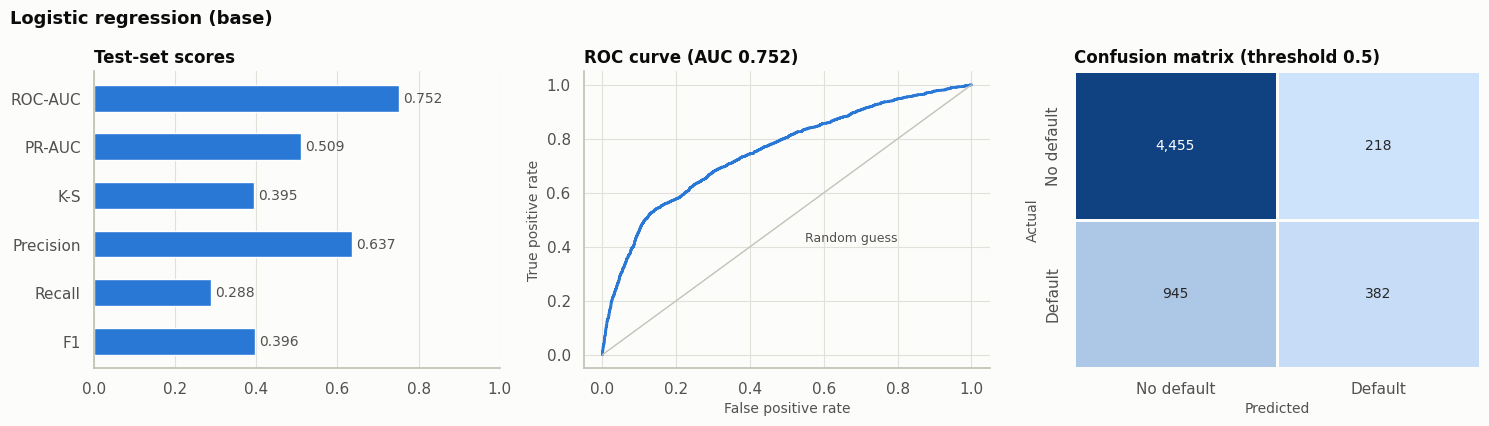

In [51]:
# Visualizing evaluation Metric Score chart
plot_model_report("Logistic regression (base)", logistic_base_proba)

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__C': np.float64(35.11191734215127)} | CV ROC-AUC: 0.7663


,ROC-AUC,PR-AUC,K-S,Brier,Precision,Recall,F1
Logistic regression (tuned),0.752,0.509,0.395,0.142,0.637,0.288,0.396


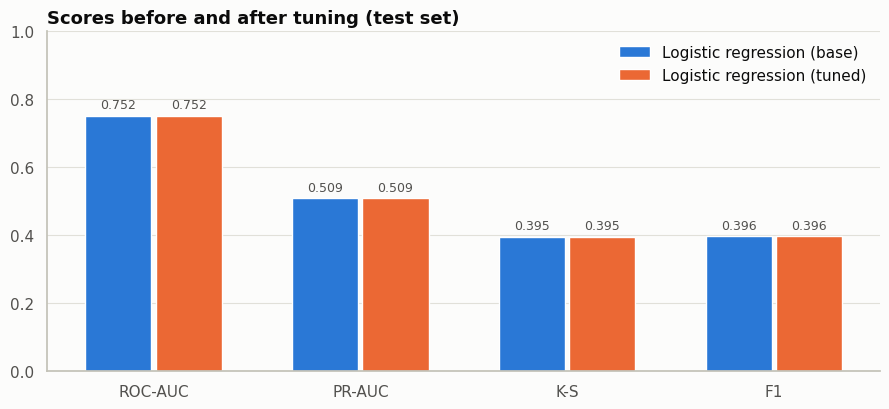

In [52]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (RandomizedSearchCV)
logistic_search = RandomizedSearchCV(
    Pipeline([("prep", linear_preprocessor()), ("clf", LogisticRegression(max_iter=3000))]),
    param_distributions={"clf__C": np.logspace(-3, 2, 12)},
    n_iter=8, cv=cv5, scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE,
).fit(X_train, y_train)
print(f"Best parameters: {logistic_search.best_params_} | CV ROC-AUC: {logistic_search.best_score_:.4f}")

logistic_tuned = logistic_search.best_estimator_
logistic_tuned_proba = evaluate("Logistic regression (tuned)", logistic_tuned)
plot_improvement("Logistic regression (base)", "Logistic regression (tuned)")

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** with 5-fold stratified cross-validation, scored on ROC-AUC. It samples combinations instead of trying all of them, so it reaches good values at a fraction of grid search's cost, and it is simple and reproducible. ROC-AUC is the scoring metric because the goal is ranking customers by risk, and it does not depend on any threshold.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**No meaningful improvement.** The best setting was C = 35 (very light regularisation) with a CV ROC-AUC of 0.766, and the test scores stay the same to three decimals (ROC-AUC 0.752, K-S 0.395). With 24,000 rows and few features the model is not overfitting, so regularisation has nothing to fix. The limit is the model's form: a linear model cannot capture the U-shape in age (Chart 12) or the jump at two months late (Chart 6), which motivates the tree-based models.

### ML Model - 2

In [53]:
# ML Model - 2 Implementation: random forest, an ensemble that captures non-linear effects
forest_base = Pipeline([("prep", tree_preprocessor()),
                        ("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE))]).fit(X_train, y_train)
forest_base_proba = evaluate("Random forest (base)", forest_base)

,ROC-AUC,PR-AUC,K-S,Brier,Precision,Recall,F1
Random forest (base),0.760,0.540,0.412,0.138,0.653,0.395,0.492


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

A random forest trains many decision trees on random subsets of rows and features and averages their votes. Trees capture non-linear effects and interactions without scaling, and averaging reduces overfitting. With default settings (200 trees) it scores **ROC-AUC 0.760, K-S 0.412 and Brier 0.138**, with precision 0.653 and recall 0.395, already better than logistic regression. Fully grown trees still memorise some noise, which tuning addresses.

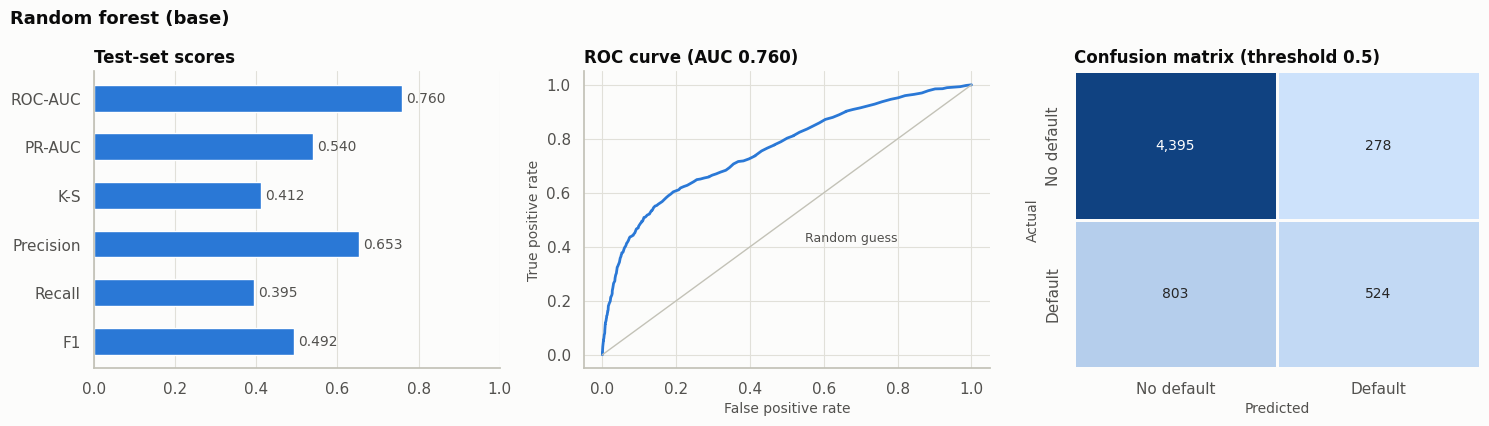

In [54]:
# Visualizing evaluation Metric Score chart
plot_model_report("Random forest (base)", forest_base_proba)

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__min_samples_leaf': 20, 'clf__max_features': 0.3, 'clf__max_depth': 16} | CV ROC-AUC: 0.7863


,ROC-AUC,PR-AUC,K-S,Brier,Precision,Recall,F1
Random forest (tuned),0.777,0.562,0.423,0.135,0.673,0.359,0.469


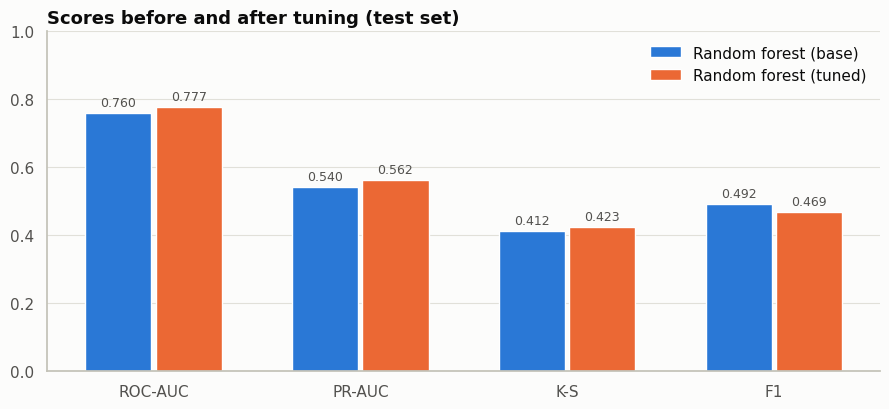

In [55]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (RandomizedSearchCV)
forest_search = RandomizedSearchCV(
    Pipeline([("prep", tree_preprocessor()), ("clf", RandomForestClassifier(n_estimators=200, n_jobs=1, random_state=RANDOM_STATE))]),
    param_distributions={"clf__max_depth": [6, 8, 10, 12, 16], "clf__min_samples_leaf": [5, 10, 20, 50],
                         "clf__max_features": ["sqrt", 0.3, 0.5]},
    n_iter=6, cv=3, scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE,
).fit(X_train, y_train)
print(f"Best parameters: {forest_search.best_params_} | CV ROC-AUC: {forest_search.best_score_:.4f}")

forest_tuned = forest_search.best_estimator_
forest_tuned_proba = evaluate("Random forest (tuned)", forest_tuned)
plot_improvement("Random forest (base)", "Random forest (tuned)")

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** with 3-fold stratified cross-validation, scored on ROC-AUC. A random forest has several interacting settings, so sampling combinations is much cheaper than a full grid. Three folds keep the runtime reasonable with 24,000 rows, and each fold still has thousands of defaulters.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Yes, for ranking and probabilities.** ROC-AUC rose from 0.760 to **0.777**, PR-AUC from 0.540 to 0.562, K-S from 0.412 to 0.423, and Brier fell from 0.138 to 0.135. The best settings (`max_depth` 16, `min_samples_leaf` 20, `max_features` 0.3) stop trees from memorising individual customers. F1 at the 0.5 threshold fell from 0.492 to 0.469, because the more realistic probabilities put fewer customers above 0.5. That is an effect of the fixed threshold, not a worse model.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

- **ROC-AUC:** how well the model ranks risky customers above safe ones. A higher value means collections and limit-review effort goes where it matters.
- **K-S:** the largest gap between the share of defaulters and the share of non-defaulters captured. It is the standard credit scorecard measure, it shows the point of best separation, and the project brief asks for it.
- **PR-AUC:** the quality of the flagged list when only 22% default, which shows how much effort is wasted as the list grows.
- **Brier score:** how accurate the probabilities are, which matters for provisions and pricing.
- **Recall:** the share of defaulters caught. Each one missed is a potential loss.
- **Precision:** the share of flagged customers who really default. Low precision means wasted effort and annoyed good customers.
- **F1:** a single balance of precision and recall, useful for comparing thresholds.

**Business impact of this model:** with ROC-AUC 0.777 and K-S 0.423, the tuned forest already gives the bank a usable ranking of who to contact first, a clear improvement on treating all customers alike.

### ML Model - 3

In [56]:
# ML Model - 3 Implementation: XGBoost, gradient boosting that builds trees to correct earlier errors
xgb_base = Pipeline([("prep", tree_preprocessor()),
                     ("clf", XGBClassifier(n_estimators=300, learning_rate=0.1, eval_metric="logloss", tree_method="hist",
                                           n_jobs=1, random_state=RANDOM_STATE))]).fit(X_train, y_train)
xgb_base_proba = evaluate("XGBoost (base)", xgb_base)

,ROC-AUC,PR-AUC,K-S,Brier,Precision,Recall,F1
XGBoost (base),0.765,0.545,0.401,0.139,0.645,0.377,0.476


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

XGBoost builds trees one after another, each correcting the errors of those before it, with built-in regularisation. It handles non-linear effects and interactions and is usually among the best methods on tabular data. With 300 trees at a learning rate of 0.1 it scores **ROC-AUC 0.765, K-S 0.401 and Brier 0.139**, with precision 0.645 and recall 0.377. Those settings learn too aggressively for noisy credit data, so tuning has real room to help.

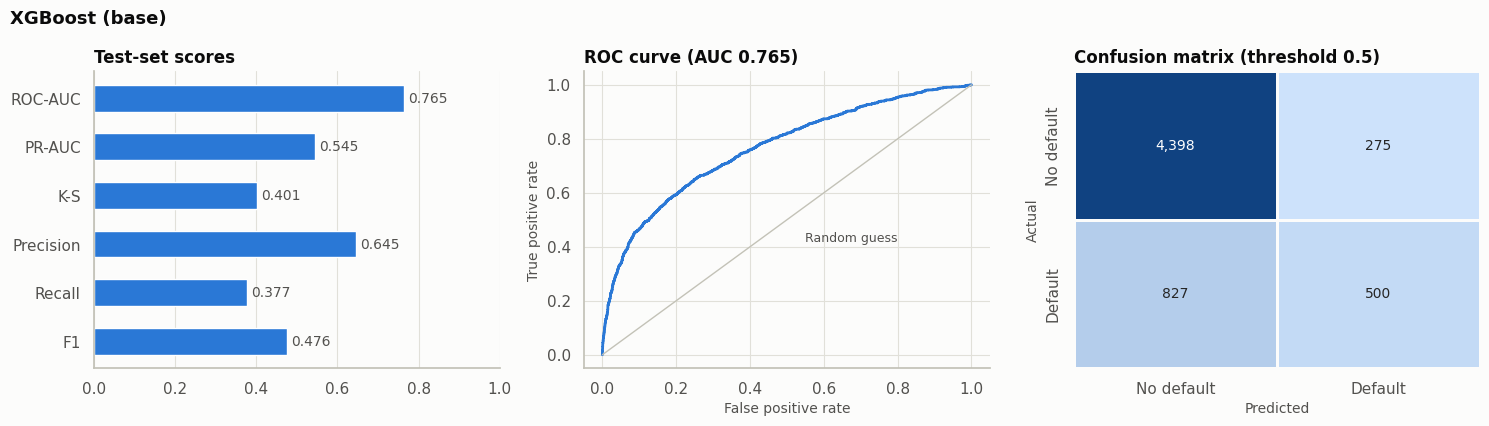

In [57]:
# Visualizing evaluation Metric Score chart
plot_model_report("XGBoost (base)", xgb_base_proba)

#### 2. Cross- Validation & Hyperparameter Tuning

Best parameters: {'clf__subsample': 0.8, 'clf__reg_lambda': 10, 'clf__n_estimators': 200, 'clf__min_child_weight': 5, 'clf__max_depth': 4, 'clf__learning_rate': 0.05, 'clf__colsample_bytree': 1.0} | CV ROC-AUC: 0.7885


,ROC-AUC,PR-AUC,K-S,Brier,Precision,Recall,F1
XGBoost (tuned),0.780,0.567,0.432,0.134,0.672,0.368,0.475


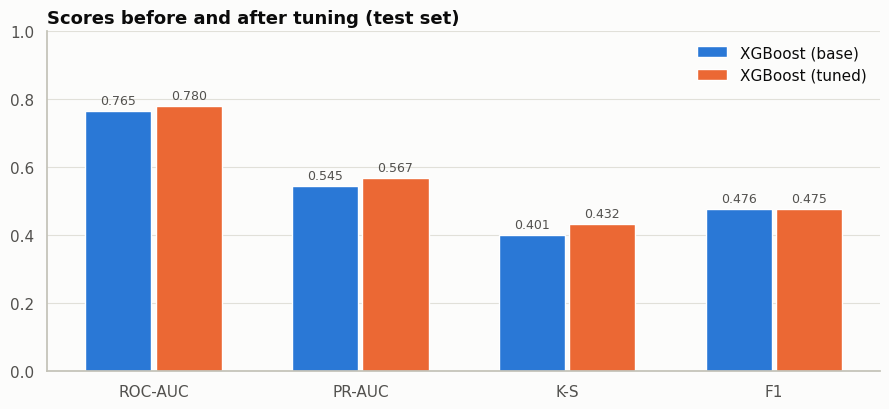

In [58]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (RandomizedSearchCV)
xgb_search = RandomizedSearchCV(
    Pipeline([("prep", tree_preprocessor()),
              ("clf", XGBClassifier(eval_metric="logloss", tree_method="hist", n_jobs=1, random_state=RANDOM_STATE))]),
    param_distributions={"clf__n_estimators": [200, 400, 600], "clf__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
                         "clf__max_depth": [2, 3, 4, 5, 6], "clf__min_child_weight": [1, 5, 10, 20],
                         "clf__subsample": [0.7, 0.8, 1.0], "clf__colsample_bytree": [0.6, 0.8, 1.0],
                         "clf__reg_lambda": [1, 5, 10]},
    n_iter=15, cv=3, scoring="roc_auc", n_jobs=-1, random_state=RANDOM_STATE,
).fit(X_train, y_train)
print(f"Best parameters: {xgb_search.best_params_} | CV ROC-AUC: {xgb_search.best_score_:.4f}")

xgb_tuned = xgb_search.best_estimator_
xgb_tuned_proba = evaluate("XGBoost (tuned)", xgb_tuned)
plot_improvement("XGBoost (base)", "XGBoost (tuned)")

##### Which hyperparameter optimization technique have you used and why?

**RandomizedSearchCV** with 3-fold stratified cross-validation, scored on ROC-AUC. XGBoost has many interacting settings, which makes a full grid impractical, so 15 sampled combinations cover the space at a sensible cost. The ranges favour many shallow trees with slow learning, which suits noisy credit data.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

**Yes, the largest improvement of the three.** ROC-AUC rose from 0.765 to **0.780**, PR-AUC from 0.545 to 0.567, K-S from 0.401 to **0.432**, and Brier fell from 0.139 to 0.134. The best settings (200 trees, learning rate 0.05, `max_depth` 4, `min_child_weight` 5, `subsample` 0.8, `reg_lambda` 10) use fewer, shallower trees that learn more slowly with stronger regularisation, which resists noise. F1 at the 0.5 threshold is about the same (0.476 to 0.475).

,ROC-AUC,PR-AUC,K-S,Brier,Precision,Recall,F1
Logistic regression (base),0.752,0.509,0.395,0.142,0.637,0.288,0.396
Logistic regression (tuned),0.752,0.509,0.395,0.142,0.637,0.288,0.396
Random forest (base),0.760,0.540,0.412,0.138,0.653,0.395,0.492
Random forest (tuned),0.777,0.562,0.423,0.135,0.673,0.359,0.469
XGBoost (base),0.765,0.545,0.401,0.139,0.645,0.377,0.476
XGBoost (tuned),0.780,0.567,0.432,0.134,0.672,0.368,0.475


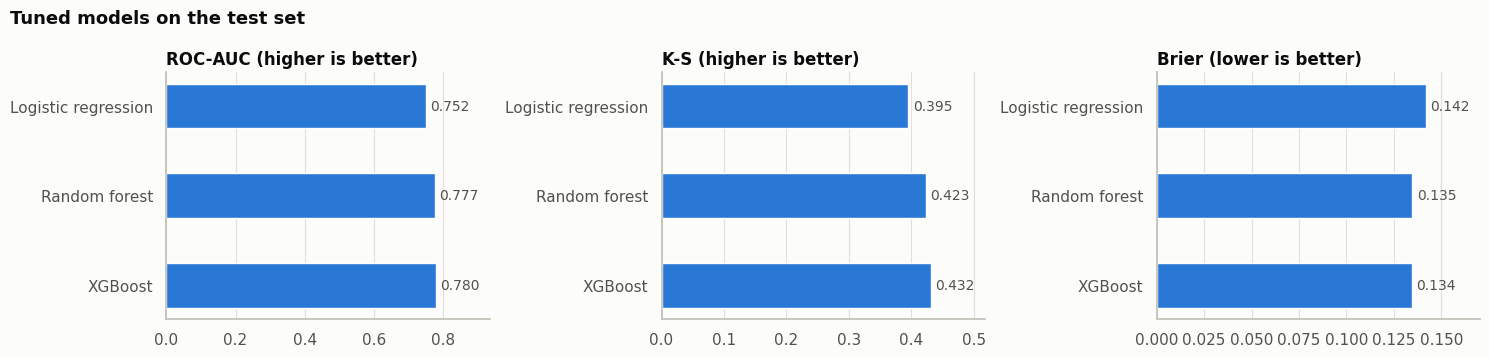

In [59]:
# ---------------- All models side by side (test set) ----------------
comparison_table = pd.DataFrame(RESULTS).T
display(comparison_table)

tuned = comparison_table.loc[["Logistic regression (tuned)", "Random forest (tuned)", "XGBoost (tuned)"]]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, metric, note in [(axes[0], "ROC-AUC", "Higher is better"), (axes[1], "K-S", "Higher is better"), (axes[2], "Brier", "Lower is better")]:
    values = tuned[metric].iloc[::-1]
    bars = ax.barh([n.replace(" (tuned)", "") for n in values.index], values.values, color=BLUE, height=0.5)
    ax.bar_label(bars, labels=[f"{v:.3f}" for v in values.values], padding=3, color=INK_2)
    ax.set_xlim(0, values.max() * 1.2)
    ax.grid(axis="y", visible=False)
    ax.set_title(f"{metric} ({note.lower()})", loc="left", fontsize=12)
fig.suptitle("Tuned models on the test set", x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

**ROC-AUC and K-S as the main measures, the Brier score for the probabilities, and precision and recall at a chosen threshold to set actions.**

The business needs a reliable probability of default, not just a label, so the model must rank customers well (ROC-AUC, K-S) and give believable probabilities (Brier, calibration). Precision and recall then turn the score into action: they show how many defaulters are caught and how many good customers are bothered at each threshold. Accuracy is not used, because always predicting "no default" would score 78% while catching nobody.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

**Tuned XGBoost.** It is the best on every ranking and probability measure on the test set:

| Test-set measure | Logistic regression | Random forest | XGBoost |
|---|---|---|---|
| ROC-AUC | 0.752 | 0.777 | **0.780** |
| K-S | 0.395 | 0.423 | **0.432** |
| PR-AUC | 0.509 | 0.562 | **0.567** |
| Brier (lower is better) | 0.142 | 0.135 | **0.134** |

The gap to the random forest is small, but XGBoost has a clearly better K-S, which the brief emphasises, and the charts below show its probabilities match actual default rates closely. Logistic regression stays useful as a simple benchmark.

K-S statistic = 0.432, reached at the riskiest 26.0% of customers (score 0.258)
At that point the list holds 59.6% of defaulters and 16.5% of non-defaulters


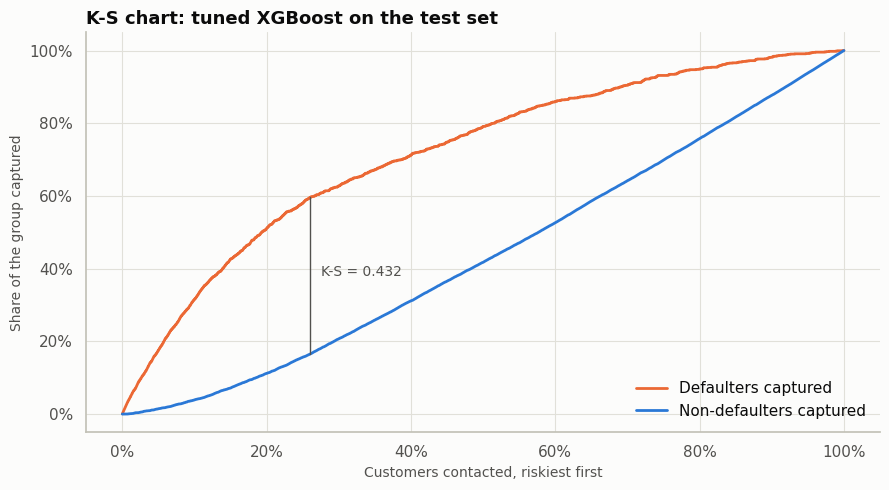

In [60]:
# ---------------- Final model: K-S chart ----------------
final_model = xgb_tuned
final_proba = xgb_tuned_proba

order = np.argsort(final_proba)[::-1]
y_sorted = y_test.values[order]
share_scored = np.arange(1, len(y_sorted) + 1) / len(y_sorted) * 100
cum_default = np.cumsum(y_sorted) / y_sorted.sum() * 100
cum_no_default = np.cumsum(1 - y_sorted) / (1 - y_sorted).sum() * 100
gap = cum_default - cum_no_default
ks_at = int(np.argmax(gap))
print(f"K-S statistic = {gap[ks_at] / 100:.3f}, reached at the riskiest {share_scored[ks_at]:.1f}% of customers (score {final_proba[order][ks_at]:.3f})")
print(f"At that point the list holds {cum_default[ks_at]:.1f}% of defaulters and {cum_no_default[ks_at]:.1f}% of non-defaulters")

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(share_scored, cum_default, color=ORANGE, label="Defaulters captured")
ax.plot(share_scored, cum_no_default, color=BLUE, label="Non-defaulters captured")
ax.plot([share_scored[ks_at]] * 2, [cum_no_default[ks_at], cum_default[ks_at]], color=INK_2, linewidth=1)
ax.text(share_scored[ks_at] + 1.5, (cum_default[ks_at] + cum_no_default[ks_at]) / 2, f"K-S = {gap[ks_at] / 100:.3f}", color=INK_2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.legend(loc="lower right")
ax.set_title("K-S chart: tuned XGBoost on the test set", loc="left")
ax.set_xlabel("Customers contacted, riskiest first")
ax.set_ylabel("Share of the group captured")
plt.tight_layout()
plt.show()

,customers,defaults,avg_predicted,actual_rate,lift,cum_defaults_captured
decile,,,,,,
1,600,419,0.713,0.698,3.157,0.316
2,600,258,0.432,0.430,1.944,0.510
3,600,156,0.273,0.260,1.176,0.628
4,600,112,0.200,0.187,0.844,0.712
5,600,105,0.163,0.175,0.791,0.791
6,600,91,0.135,0.152,0.686,0.860
7,600,59,0.110,0.098,0.445,0.904
8,600,59,0.087,0.098,0.445,0.949
9,600,44,0.065,0.073,0.332,0.982


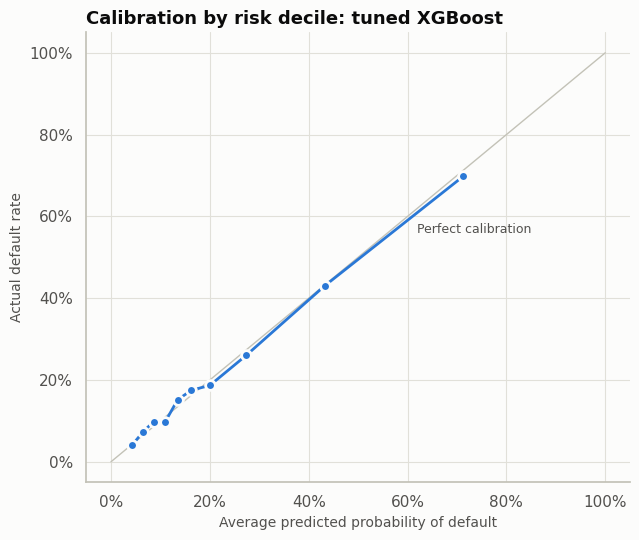

In [61]:
# ---------------- Final model: gains table and calibration ----------------
scored = pd.DataFrame({"actual": y_test.values, "predicted": final_proba})
scored["decile"] = pd.qcut(scored["predicted"].rank(method="first"), 10, labels=range(10, 0, -1)).astype(int)   # 1 = riskiest
gains = scored.groupby("decile").agg(customers=("actual", "size"), defaults=("actual", "sum"),
                                     avg_predicted=("predicted", "mean"), actual_rate=("actual", "mean"))
gains["lift"] = gains["actual_rate"] / y_test.mean()
gains["cum_defaults_captured"] = gains["defaults"].cumsum() / gains["defaults"].sum()
display(gains.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.plot([0, 1], [0, 1], color=AXIS, linewidth=1)
ax.text(0.62, 0.56, "Perfect calibration", color=INK_2, fontsize=9)
ax.plot(gains["avg_predicted"], gains["actual_rate"], color=BLUE, marker="o", markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_title("Calibration by risk decile: tuned XGBoost", loc="left")
ax.set_xlabel("Average predicted probability of default")
ax.set_ylabel("Actual default rate")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
plt.tight_layout()
plt.show()

In [62]:
# ---------------- Final model: choosing a decision threshold without touching the test set ----------------
# Out-of-fold predictions on the training set stand in for new customers
train_oof = cross_val_predict(final_model, X_train, y_train, cv=cv5, method="predict_proba")[:, 1]
thresholds = np.round(np.arange(0.05, 0.71, 0.01), 2)
MISSED_DEFAULT_COST = 5                # assumption: missing a defaulter costs five times a false alarm; the bank should set this


def expected_cost(threshold):
    """Cost units from missed defaults and false alarms at a threshold."""
    missed = ((train_oof < threshold) & (y_train == 1)).sum()
    false_alarms = ((train_oof >= threshold) & (y_train == 0)).sum()
    return MISSED_DEFAULT_COST * missed + false_alarms


best_f1_threshold = thresholds[int(np.argmax([f1_score(y_train, train_oof >= t) for t in thresholds]))]
best_cost_threshold = thresholds[int(np.argmin([expected_cost(t) for t in thresholds]))]

rows = {}
for label, threshold in [("Default 0.50", 0.50), (f"Best F1 ({best_f1_threshold:.2f})", best_f1_threshold), (f"Lowest cost at 5:1 ({best_cost_threshold:.2f})", best_cost_threshold)]:
    predicted = final_proba >= threshold
    rows[label] = {"flagged_share": predicted.mean(), "precision": precision_score(y_test, predicted),
                   "recall": recall_score(y_test, predicted), "f1": f1_score(y_test, predicted)}
display(pd.DataFrame(rows).T.round(3))

# Risk tiers a bank could act on directly
tiers = pd.cut(final_proba, bins=[0, 0.15, 0.30, 0.50, 1], labels=["Low (under 15%)", "Moderate (15-30%)", "High (30-50%)", "Very high (over 50%)"])
tier_table = pd.DataFrame({"tier": tiers, "actual": y_test.values}).groupby("tier", observed=True)["actual"].agg(customers="size", defaults="sum", actual_rate="mean")
tier_table["share_of_customers"] = tier_table["customers"] / tier_table["customers"].sum()
tier_table["share_of_defaults"] = tier_table["defaults"] / tier_table["defaults"].sum()
display(tier_table.round(3))

,flagged_share,precision,recall,f1
Default 0.50,0.121,0.672,0.368,0.475
Best F1 (0.29),0.231,0.534,0.558,0.546
Lowest cost at 5:1 (0.16),0.458,0.364,0.754,0.491


,customers,defaults,actual_rate,share_of_customers,share_of_defaults
tier,,,,,
Low (under 15%),3035,285,0.094,0.506,0.215
Moderate (15-30%),1621,315,0.194,0.270,0.237
High (30-50%),618,239,0.387,0.103,0.180
Very high (over 50%),726,488,0.672,0.121,0.368


**What these results mean for the bank**

- **K-S chart:** the gap between the two curves peaks at **0.432** among the riskiest 26% of customers, where the list holds about 60% of defaulters and only 17% of non-defaulters.
- **Gains table:** the riskiest 10% default at **69.8%**, 3.2 times the average, and the riskiest 30% contain **63% of all defaults**. The safest 10% default at only 4.0%.
- **Calibration:** predicted and actual rates track closely across deciles (71.3% predicted against 69.8% actual in the riskiest decile), so the probabilities can be used directly, which is what the brief asks for.
- **Thresholds:** the default 0.50 catches only 36.8% of defaulters. A threshold of 0.29 (the best F1, chosen on training data) flags 23.1% of customers and catches 55.8%, while 0.16 (the lowest cost if a missed default costs five times a false alarm, which is an assumption the bank should replace) flags 45.8% and catches 75.4%.
- **Risk tiers:** the Very high and High tiers are 22.4% of customers but hold 54.8% of defaults. The Low tier is half of all customers, at a 9.4% default rate.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

XGBoost combines hundreds of small trees, so no single rule explains a prediction. Two tools make it readable. **Permutation importance** measures how much test ROC-AUC drops when one feature is shuffled. **SHAP** shows how each feature's value pushes an individual customer's prediction up or down.

,MAX_DELAY,PAY_1,AVG_PAYMENT,UTILIZATION,LIMIT_BAL,PAY_AMT1,BILL_TREND,NUM_LATE_MONTHS,REPAY_RATIO,PAY_AMT2,EDUCATION,AGE,MARRIAGE,PAY_2
drop_in_roc_auc,0.036,0.032,0.017,0.013,0.007,0.004,0.004,0.004,0.003,0.002,0.001,0.001,0.001,0.000


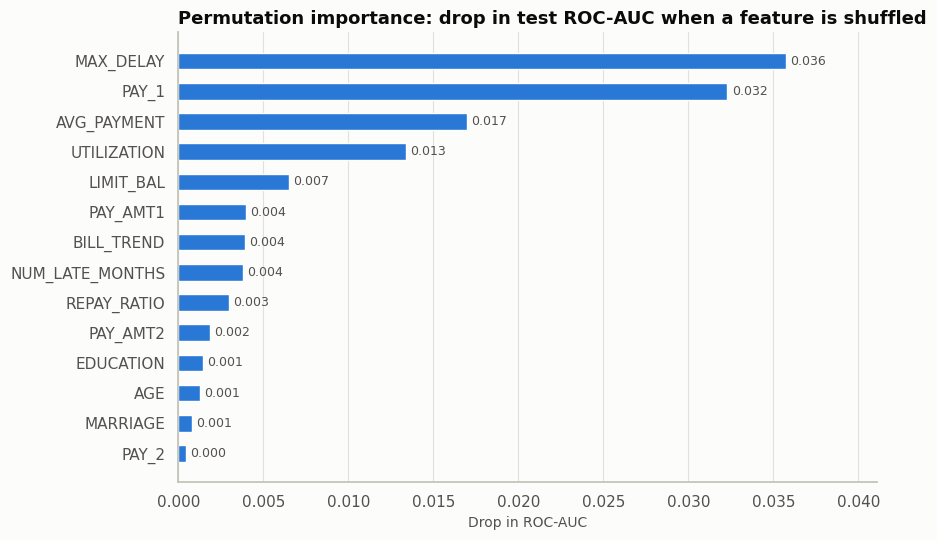

In [63]:
# ---------------- Explainability 1: permutation importance on the test set ----------------
perm = permutation_importance(final_model, X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
display(importance.iloc[::-1].to_frame("drop_in_roc_auc").T)

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(importance.index, importance.values, color=BLUE, height=0.55)
ax.bar_label(bars, labels=[f"{v:.3f}" for v in importance.values], padding=3, color=INK_2, fontsize=9)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, importance.max() * 1.15)
ax.set_title("Permutation importance: drop in test ROC-AUC when a feature is shuffled", loc="left")
ax.set_xlabel("Drop in ROC-AUC")
plt.tight_layout()
plt.show()

,MAX_DELAY,PAY_1,AVG_PAYMENT,UTILIZATION,LIMIT_BAL,NUM_LATE_MONTHS,BILL_TREND,PAY_AMT1
mean_abs_shap,0.456,0.307,0.143,0.135,0.125,0.111,0.091,0.078


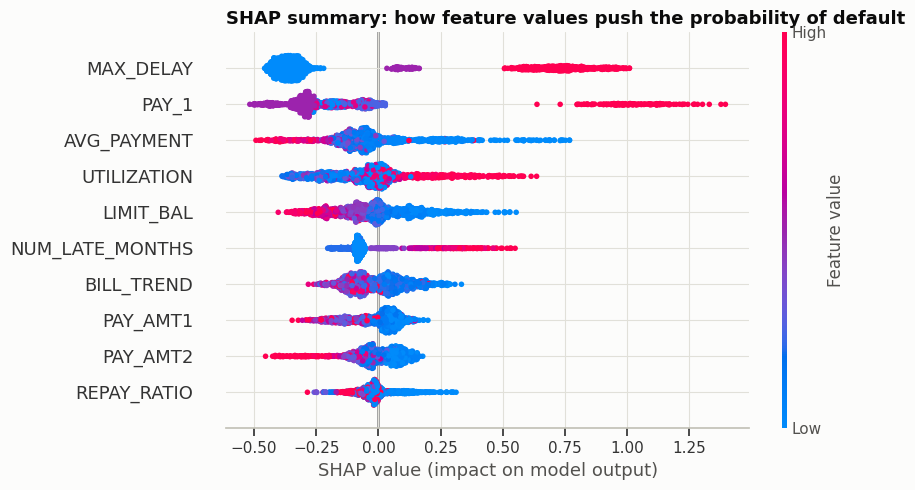

In [64]:
# ---------------- Explainability 2: SHAP values for how each feature pushes a prediction ----------------
try:
    prep, booster = final_model.named_steps["prep"], final_model.named_steps["clf"]
    shap_rows = X_test.sample(1500, random_state=RANDOM_STATE)
    encoded = pd.DataFrame(prep.transform(shap_rows), columns=prep.get_feature_names_out(), index=shap_rows.index)
    shap_values = shap.TreeExplainer(booster).shap_values(encoded)
    mean_impact = pd.Series(np.abs(shap_values).mean(axis=0), index=encoded.columns).sort_values(ascending=False)
    display(mean_impact.head(8).round(3).to_frame("mean_abs_shap").T)
    shap.summary_plot(shap_values, encoded, max_display=10, show=False, plot_size=(9, 5))
    plt.title("SHAP summary: how feature values push the probability of default", loc="left", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()
except Exception as shap_error:          # explainability is a bonus view; never let it stop the notebook
    print(f"SHAP plot skipped ({type(shap_error).__name__}: {shap_error}); permutation importance above still applies.")

**Repayment behaviour dominates, and both tools agree.**

- **Permutation importance:** `MAX_DELAY` (0.036) and `PAY_1` (0.032) lead, followed by `AVG_PAYMENT` (0.017), `UTILIZATION` (0.013) and `LIMIT_BAL` (0.007).
- **SHAP:** `MAX_DELAY` (0.456) and `PAY_1` (0.307) lead, followed by `AVG_PAYMENT` (0.143), `UTILIZATION` (0.135) and `LIMIT_BAL` (0.125).
- **Direction:** longer delays and higher utilisation push the probability of default up, while higher payments and higher limits push it down.
- **Demographics barely matter:** shuffling `EDUCATION` or `MARRIAGE` drops ROC-AUC by only 0.001 each.

For the bank, this means the score rests on what customers do rather than who they are, which is easier to defend and easier for customers to change.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [65]:
# Save the File
MODEL_FILE = "credit_default_xgb.joblib"
joblib.dump(final_model, MODEL_FILE)
print(f"Saved the fitted pipeline (pre-processing + model) to {MODEL_FILE}")

Saved the fitted pipeline (pre-processing + model) to credit_default_xgb.joblib


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [66]:
# Load the File and predict unseen data.
loaded_model = joblib.load(MODEL_FILE)
assert np.allclose(loaded_model.predict_proba(X_test)[:, 1], final_proba), "The reloaded model gives different predictions"

unseen = X_test.sample(5, random_state=RANDOM_STATE)
preview = unseen[["LIMIT_BAL", "PAY_1", "NUM_LATE_MONTHS", "UTILIZATION", "REPAY_RATIO"]].copy()
preview["probability_of_default"] = loaded_model.predict_proba(unseen)[:, 1]
preview["actual_default"] = y_test.loc[unseen.index]
display(preview.round(3))
print("The reloaded model reproduces the test-set predictions exactly.")

,LIMIT_BAL,PAY_1,NUM_LATE_MONTHS,UTILIZATION,REPAY_RATIO,probability_of_default,actual_default
20639,260000,0,4,0.629,0.055,0.426,1
7660,80000,2,1,0.987,0.031,0.675,1
13980,360000,-2,0,0.002,1.000,0.159,0
7162,90000,2,1,0.999,0.045,0.658,0
24017,50000,-1,0,0.116,0.817,0.108,0


The reloaded model reproduces the test-set predictions exactly.


# **Conclusion**

This project built a model that estimates each customer's probability of defaulting on the next credit card payment, using data on 30,000 customers in Taiwan.

**Answers to the project questions**
- **Credit by gender:** women are 60.4% of customers and hold 61.3% of credit, with a higher median limit (NT\$150,000 against NT\$130,000).
- **Past payment history:** most customers show no delay in any month. The late share rises to 22.7% in September, with the caveat that the "1 month late" code barely appears before then.
- **Are less educated customers more likely to default?** Yes, modestly: 19.2% for graduate school, 23.7% for university and 25.2% for high school (Cramér's V 0.07).
- **Is marital status related to default?** Yes, but barely: 23.5% for married and 20.9% for single customers (Cramér's V 0.03).
- **What signals default?** Behaviour, not demographics: repayment status, repeated lateness, how much customers pay back and how much of their limit they use.

**Model:** tuned XGBoost reaches ROC-AUC 0.780, K-S 0.432 and Brier 0.134 on unseen customers. Its riskiest 10% default at 69.8%, 3.2 times the average, and its riskiest 30% contain 63% of all defaults. Its probabilities closely match actual rates.

**Recommendation for the bank:** act on the probability in tiers.

| Tier | Share of customers | Actual default rate | Suggested action |
|---|---|---|---|
| Very high (over 50%) | 12.1% | 67.2% | Contact now, offer a payment plan, freeze limit increases |
| High (30–50%) | 10.3% | 38.7% | Early reminders and a limit review |
| Moderate (15–30%) | 27.0% | 19.4% | Monitor monthly, especially utilisation and payment amounts |
| Low (under 15%) | 50.6% | 9.4% | Keep limits, and consider increases for reliable payers |

The bank should set the final cut-off from its own costs. For example, a threshold of 0.29 flags 23% of customers and catches 56% of defaulters, while 0.16 flags 46% and catches 75%.

**Limitations**
- The data covers six months in Taiwan in 2005, so patterns may not transfer to other markets or years without retraining and a test on later data.
- Some codes are undocumented, and the "1 month late" code behaves differently in September.
- The 5-to-1 cost ratio is an assumption for illustration, not a measured figure.
- Age, education and marital status remain in the model and need a legal and fairness review before real use.
- There is no income or spending data, which would likely improve the model.

**Next steps:** test on later data, add a fairness review, add income and transaction features, and deploy the saved pipeline behind an API or a Streamlit app with monitoring. Azure Machine Learning, Streamlit and GenAI were not used in this version; the saved pipeline makes them straightforward to add later.